In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import hashlib, json, shutil, zipfile, platform, html, base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display, HTML
except ImportError:
    display = print
    HTML = lambda value: value

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/obp_utils.py').exists()), Path.cwd())
RAW = ROOT / 'data/raw/hitting'
OUT = ROOT / 'results/rotation_onset_orientation'
FIG = ROOT / 'figures/rotation_onset_orientation'
for folder in (RAW, OUT, FIG):
    folder.mkdir(parents=True, exist_ok=True)
AUTO_DOWNLOAD = True
MAKE_POSE = True
LOAD_OPTIONAL_OUTCOMES = True
SELECTED_SWING = None
MIN_VALID_SWINGS = 5
LOOKBACK_S = .150
FLOOR_DPS = 60.
PEAK_FRACTION = .15
SUSTAIN_S = .010
PRE_ONSET_S = .010
EVENTS = ['fp_10_time', 'fp_100_time', 'contact_time']
CHANNELS = [s+'_angle_'+a for s in ('pelvis','torso') for a in 'xyz']
RATES = [s+'_angular_velocity_z' for s in ('pelvis','torso')]
GROUP = ['user','session','hitter_side']
OUTCOMES = ['bat_speed_mph_contact_x','blast_bat_speed_mph_x','exit_velo_mph_x','attack_angle_contact_x']
HASHES = {'joint_angles':'98a405c5c4a27c1a599d3e30b39a3087180cc4d4bb69faf62204a1c06881be95',
          'joint_velos':'3822dbce30988bc554ee533e5ccc12a5a3e92a53e185fdcb1cc8ad218dd464e4',
          'landmarks':'9cc2bdc94f5f5a6c5d540f4abe459caae2c5164cd53f6a6fd23f4b2b7283bcb3'}
BASE = 'https://github.com/drivelineresearch/openbiomechanics/releases/download/dataset-v1/'
CSV_BASE = 'https://raw.githubusercontent.com/drivelineresearch/openbiomechanics/dataset-v1/baseball_hitting/data/'
plt.style.use('seaborn-v0_8-whitegrid')
print('Study 19 | Pelvis and torso orientation at rotation onset')
print('Retrospective motion-capture assessment, not a live swing-start detector.')
print('Primary snapshot: both segments at pelvis onset. Pre-onset: 10 ms before the earlier detected onset.')
print('X: pelvis posterior(+)/anterior(-) tilt; torso extension(+)/flexion(-). Y: tilt toward(+)/away(-) from rear leg.')
print('Z: rotation toward(+)/away(-) from mound. No extra left/right mirroring is applied.')
print('Thresholds and search windows are analytical choices. No ideal posture or causal benefit is assumed.')
print('First run downloads about 155 MB of signal archives; optional landmarks add about 66 MB.')

Study 19 | Pelvis and torso orientation at rotation onset
Retrospective motion-capture assessment, not a live swing-start detector.
Primary snapshot: both segments at pelvis onset. Pre-onset: 10 ms before the earlier detected onset.
X: pelvis posterior(+)/anterior(-) tilt; torso extension(+)/flexion(-). Y: tilt toward(+)/away(-) from rear leg.
Z: rotation toward(+)/away(-) from mound. No extra left/right mirroring is applied.
Thresholds and search windows are analytical choices. No ideal posture or causal benefit is assumed.
First run downloads about 155 MB of signal archives; optional landmarks add about 66 MB.


In [2]:
def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()

def download(url, path):
    if not AUTO_DOWNLOAD:
        raise FileNotFoundError(f'Missing {path}; supply official Dataset v1 data or enable AUTO_DOWNLOAD.')
    print('Downloading', path.name, flush=True)
    tmp = path.with_suffix(path.suffix+'.part')
    urlretrieve(url, tmp)
    tmp.replace(path)

def ensure_signal(name):
    target = RAW / (name+'.csv')
    if target.exists():
        return target
    archive = RAW / ('hitting_'+name+'.zip')
    if not archive.exists():
        download(BASE+archive.name, archive)
    if sha256(archive) != HASHES[name]:
        raise ValueError('Archive checksum mismatch: '+archive.name)
    with zipfile.ZipFile(archive) as z:
        matches = [n for n in z.namelist() if Path(n).name == target.name]
        if len(matches) != 1:
            raise ValueError('Expected one '+target.name)
        tmp = target.with_suffix('.csv.part')
        with z.open(matches[0]) as s, tmp.open('wb') as d:
            shutil.copyfileobj(s,d)
        tmp.replace(target)
    return target

def check_keys(df, name, keys):
    if df[keys].isna().any().any() or df.duplicated(keys).any():
        raise ValueError('Missing or duplicate keys: '+name)

angles = pd.read_csv(ensure_signal('joint_angles'), usecols=['session_swing','time']+EVENTS+CHANNELS,
                     dtype={'session_swing':str})
velos = pd.read_csv(ensure_signal('joint_velos'), usecols=['session_swing','time']+EVENTS+RATES,
                    dtype={'session_swing':str})
if not (RAW/'metadata.csv').exists():
    download(CSV_BASE+'metadata.csv', RAW/'metadata.csv')
metadata = pd.read_csv(RAW/'metadata.csv',dtype={'session_swing':str,'user':str,'session':str})
check_keys(metadata,'metadata',['session_swing'])
for name,df in [('angles',angles),('velocities',velos)]:
    check_keys(df,name,['session_swing','time'])
if metadata[GROUP].isna().any().any() or not metadata.hitter_side.isin(['L','R']).all():
    raise ValueError('Missing hitter/session identity or unsupported batting side')
ag = {str(k):g.sort_values('time').reset_index(drop=True) for k,g in angles.groupby('session_swing',sort=False)}
vg = {str(k):g.sort_values('time').reset_index(drop=True) for k,g in velos.groupby('session_swing',sort=False)}
meta = metadata.set_index('session_swing')
poi = pd.DataFrame(columns=['session_swing']+OUTCOMES)
if LOAD_OPTIONAL_OUTCOMES:
    try:
        if not (RAW/'poi_metrics.csv').exists():
            download(CSV_BASE+'poi/poi_metrics.csv',RAW/'poi_metrics.csv')
        poi = pd.read_csv(RAW/'poi_metrics.csv',dtype={'session_swing':str})
        check_keys(poi,'POI',['session_swing'])
    except OSError as exc:
        print('Optional outcomes unavailable:',exc)
for c in OUTCOMES:
    if c not in poi:
        poi[c] = np.nan
print(f'{len(ag)} angle trials; {len(vg)} velocity trials; {metadata.user.nunique()} hitters')

677 angle trials; 677 velocity trials; 98 hitters


In [3]:
def event_values(g):
    if g is None or g.empty:
        raise ValueError('missing signal table')
    e = {}
    for c in EVENTS:
        x = g[c].to_numpy(float)
        if not np.isfinite(x).all() or np.ptp(x)>1e-7:
            raise ValueError('missing/inconsistent event '+c)
        e[c] = float(x[0])
    if not e[EVENTS[0]] < e[EVENTS[1]] < e[EVENTS[2]]:
        raise ValueError('unordered events')
    return e

def window(g, cols, lo, hi, unwrap=False):
    t = g.time.to_numpy(float)
    if not np.isfinite(t).all() or len(t)<3 or np.any(np.diff(t)<=0):
        raise ValueError('invalid time grid')
    if lo<t[0]-1e-9 or hi>t[-1]+1e-9 or lo>=hi:
        raise ValueError('window outside recording')
    left = max(0,np.searchsorted(t,lo,side='right')-1)
    right = min(len(t),np.searchsorted(t,hi,side='left')+1)
    tt = t[left:right]
    dt = np.median(np.diff(tt))
    if len(tt)<3 or not np.allclose(np.diff(tt),1/360,rtol=.03,atol=.00011):
        raise ValueError('sampling gap or unexpected sampling rate')
    x = g[cols].to_numpy(float)[left:right].copy()
    if not np.isfinite(x).all():
        raise ValueError('nonfinite requested signal')
    if unwrap:
        x = np.rad2deg(np.unwrap(np.deg2rad(x),axis=0))
    grid = np.r_[lo,tt[(tt>lo+1e-10)&(tt<hi-1e-10)],hi]
    return grid,np.column_stack([np.interp(grid,tt,x[:,i]) for i in range(len(cols))])

def onset(t, rate, floor=FLOOR_DPS, fraction=PEAK_FRACTION, sustain=SUSTAIN_S):
    t,rate = np.asarray(t,float),np.asarray(rate,float)
    if len(t)!=len(rate) or len(t)<3 or not np.isfinite(rate).all() or not np.isfinite(t).all() or np.any(np.diff(t)<=0):
        raise ValueError('invalid onset inputs')
    if floor<=0 or not 0<=fraction<1 or sustain<=0:
        raise ValueError('invalid onset settings')
    threshold = max(floor,fraction*max(0.,float(rate.max())))
    above = rate>=threshold
    starts = np.flatnonzero(above & ~np.r_[False,above[:-1]])
    ends = np.flatnonzero(above & ~np.r_[above[1:],False])
    for a,b in zip(starts,ends):
        if t[b]-t[a]>=sustain-1e-10:
            if a==0:
                return {'state':'left_censored','time':np.nan,'threshold':threshold}
            crossing = t[a-1]+(threshold-rate[a-1])*(t[a]-t[a-1])/(rate[a]-rate[a-1])
            return {'state':'detected','time':float(crossing),'threshold':threshold}
    return {'state':'not_detected','time':np.nan,'threshold':threshold}

def extract(key, lookback=LOOKBACK_S, floor=FLOOR_DPS, fraction=PEAK_FRACTION, sustain=SUSTAIN_S):
    a,v = ag.get(key),vg.get(key)
    e,ev = event_values(a),event_values(v)
    if any(abs(e[c]-ev[c])>1e-4 for c in EVENTS):
        raise ValueError('angle/velocity event disagreement')
    if key not in meta.index:
        raise ValueError('missing metadata match')
    lo,hi = e['fp_10_time']-lookback,e['contact_time']
    t,r = window(v,RATES,lo,hi)
    ta,x = window(a,CHANNELS,lo-PRE_ONSET_S,hi,unwrap=True)
    row = {'session_swing':key,**{c:meta.loc[key,c] for c in GROUP},**e}
    row['plant_contact_ms'] = 1000*(hi-e['fp_100_time'])
    row['duration_reference_80_200ms'] = 80<=row['plant_contact_ms']<=200
    ds = {}
    for j,s in enumerate(('pelvis','torso')):
        d = onset(t,r[:,j],floor,fraction,sustain)
        ds[s] = d
        row[s+'_state'],row[s+'_onset_s'],row[s+'_threshold_dps'] = d['state'],d['time'],d['threshold']
    pair = all(ds[s]['state']=='detected' for s in ds)
    row['onset_lag_ms'] = 1000*(ds['torso']['time']-ds['pelvis']['time']) if pair else np.nan
    row['onset_order'] = ('unresolved' if abs(row['onset_lag_ms'])<=1000/360 else
                          'pelvis first' if row['onset_lag_ms']>0 else 'torso first') if pair else 'incomplete'
    snaps = {'pelvis_onset':ds['pelvis']['time'],'torso_onset':ds['torso']['time'],
             'pre_onset':min(ds['pelvis']['time'],ds['torso']['time'])-PRE_ONSET_S if pair else np.nan}
    for label,when in snaps.items():
        row[label+'_snapshot_s'] = when
        for j,c in enumerate(CHANNELS):
            row[label+'__'+c] = float(np.interp(when,ta,x[:,j])) if np.isfinite(when) else np.nan
    for s in ('pelvis','torso'):
        row[s+'_pre_to_common_change_deg'] = row['pelvis_onset__'+s+'_angle_x']-row['pre_onset__'+s+'_angle_x']
    return row,{'time':t,'rates':r,'angle_time':ta,'angles':x,'events':e}

def run_extraction(**settings):
    rows,audit = [],[]
    for key in ag:
        try:
            row,_ = extract(key,**settings)
            rows.append(row)
            audit.append({'session_swing':key,'status':'processed', 'pelvis_state':row['pelvis_state'],'torso_state':row['torso_state']})
        except ValueError as exc:
            audit.append({'session_swing':key,'status':str(exc),'pelvis_state':'unavailable','torso_state':'unavailable'})
    return pd.DataFrame(rows),pd.DataFrame(audit)

t = np.arange(0,.101,1/360)
r = np.where(t<.03,0.,200.)
d = onset(t,r)
assert d['state']=='detected' and .027<d['time']<.031
assert onset(t,np.full(len(t),200.))['state']=='left_censored'
r2 = np.zeros(len(t));r2[10:12]=200
assert onset(t,r2)['state']=='not_detected'
assert onset(t,np.zeros(len(t)))['state']=='not_detected'
wrapped = np.array([179.,-179.,-177.])
assert np.allclose(np.rad2deg(np.unwrap(np.deg2rad(wrapped))),[179,181,183])
toy = pd.DataFrame({'time':np.arange(30)/360,'value':2*np.arange(30)/360+3})
tt,xx = window(toy,['value'],.010,.060)
assert np.isclose(tt[0],.010) and np.isclose(tt[-1],.060)
assert np.allclose(xx[:,0],2*tt+3)
try:
    window(toy.drop(index=12),['value'],.010,.060)
except ValueError:
    pass
else:
    raise AssertionError('A sampling gap was accepted')
print('Checks passed: sustained crossings, brief spikes, censoring, angle wrapping, exact interpolation and gap rejection.')

Checks passed: sustained crossings, brief spikes, censoring, angle wrapping, exact interpolation and gap rejection.


In [4]:
features,audit = run_extraction()
if features.empty:
    display(audit.status.value_counts())
    raise ValueError('No valid signal trials; inspect exclusion audit.')
features = features.merge(poi[['session_swing']+OUTCOMES],on='session_swing',how='left',validate='one_to_one')
common = features.loc[features.pelvis_state.eq('detected')].copy()
if common.empty:
    raise ValueError('No detected pelvis onsets; inspect threshold and coverage audits.')
PRIMARY = ['pelvis_onset__'+c for c in CHANNELS]
profile = common.groupby(GROUP,sort=False)[PRIMARY].agg(['mean','std'])
profile.columns = ['__'.join(c) for c in profile.columns]
counts = common.groupby(GROUP).size().rename('n_swings')
profile = profile.join(counts).reset_index()
profile['eligible'] = profile.n_swings>=MIN_VALID_SWINGS
profile['profile_id'] = profile[GROUP].astype(str).agg(' / '.join,axis=1)
eligibility = pd.DataFrame([{'minimum_swings':n,'eligible_profiles':int((profile.n_swings>=n).sum())} for n in (4,5,6)])
features.to_csv(OUT/'swing_features.csv',index=False)
audit.to_csv(OUT/'exclusion_audit.csv',index=False)
profile.to_csv(OUT/'session_profiles.csv',index=False)
eligibility.to_csv(OUT/'profile_eligibility_sensitivity.csv',index=False)
display(audit.groupby(['status','pelvis_state','torso_state'],dropna=False).size().rename('swings').to_frame())
display(eligibility)
print(f'{len(common)} swings have a detected pelvis onset; {int(profile.eligible.sum())} profiles meet the {MIN_VALID_SWINGS}-swing minimum.')
print('Incomplete torso detections do not remove otherwise valid common pelvis-onset snapshots.')
print('SD describes observed within-session spread, not test-retest reliability or uncertainty in the mean.')

swings
status                                 pelvis_state torso_state          
missing/inconsistent event fp_100_time unavailable  unavailable        12
missing/inconsistent event fp_10_time  unavailable  unavailable        15
processed                              detected     detected          641
                                                    left_censored       1
unordered events                       unavailable  unavailable         8

,minimum_swings,eligible_profiles
0,4,94
1,5,87
2,6,64


642 swings have a detected pelvis onset; 87 profiles meet the 5-swing minimum.
Incomplete torso detections do not remove otherwise valid common pelvis-onset snapshots.
SD describes observed within-session spread, not test-retest reliability or uncertainty in the mean.


In [5]:
configs = {'primary':{},'floor_40':{'floor':40.},'floor_80':{'floor':80.},
           'fraction_10':{'fraction':.10},'fraction_20':{'fraction':.20},
           'sustain_15ms':{'sustain':.015},'lookback_100ms':{'lookback':.100},'lookback_200ms':{'lookback':.200}}
reference = common.set_index('session_swing')
sensitivity_rows,paired_rows = [],[]
for name,settings in configs.items():
    alt = features if name=='primary' else run_extraction(**settings)[0]
    if alt.empty:
        sensitivity_rows.append({'setting':name,'processed':0,'detected_pelvis':0,'paired_swings':0})
        continue
    processed_n = len(alt)
    alt = alt.loc[alt.pelvis_state.eq('detected')].set_index('session_swing')
    keys = reference.index.intersection(alt.index)
    timing = 1000*(alt.loc[keys,'pelvis_onset_s']-reference.loc[keys,'pelvis_onset_s'])
    summary = {'setting':name,'processed':processed_n,
               'detected_pelvis':len(alt),'paired_swings':len(keys),
               'median_absolute_onset_shift_ms':timing.abs().median(),
               'p90_absolute_onset_shift_ms':timing.abs().quantile(.9)}
    for s in ('pelvis','torso'):
        c = 'pelvis_onset__'+s+'_angle_x'
        change = alt.loc[keys,c]-reference.loc[keys,c]
        summary[s+'_median_absolute_angle_shift_deg'] = change.abs().median()
        summary[s+'_p90_absolute_angle_shift_deg'] = change.abs().quantile(.9)
    sensitivity_rows.append(summary)
    for key in keys:
        paired_rows.append({'setting':name,'session_swing':key,'onset_shift_ms':timing.loc[key],
                           **{s+'_angle_shift_deg':alt.loc[key,'pelvis_onset__'+s+'_angle_x']-reference.loc[key,'pelvis_onset__'+s+'_angle_x'] for s in ('pelvis','torso')}})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(OUT/'onset_sensitivity_summary.csv',index=False)
pd.DataFrame(paired_rows).to_csv(OUT/'onset_sensitivity_paired.csv',index=False)
reference_counts = common.groupby(GROUP).size().rename('all_valid').to_frame().join(
    common.loc[common.duration_reference_80_200ms].groupby(GROUP).size().rename('duration_reference')).fillna(0)
reference_counts.to_csv(OUT/'duration_reference_profile_counts.csv')
display(sensitivity.round(2))
print('Paired differences use the same swings within each comparison; detection counts expose cohort changes.')
print('The search threshold uses the later pre-contact peak: this is an offline estimate, not ground truth.')
print('A pre-onset snapshot is relative to this detector; it does not guarantee that all movement has not begun.')

,setting,processed,detected_pelvis,paired_swings,median_absolute_onset_shift_ms,p90_absolute_onset_shift_ms,pelvis_median_absolute_angle_shift_deg,pelvis_p90_absolute_angle_shift_deg,torso_median_absolute_angle_shift_deg,torso_p90_absolute_angle_shift_deg
0,primary,642,642,642,0.00,0.00,0.00,0.00,0.00,0.00
1,floor_40,642,642,642,0.00,0.00,0.00,0.00,0.00,0.00
2,floor_80,642,642,642,0.00,0.00,0.00,0.00,0.00,0.00
3,fraction_10,642,639,639,8.08,13.57,0.26,0.65,0.16,0.45
4,fraction_20,642,642,642,6.78,10.85,0.25,0.61,0.15,0.40
5,sustain_15ms,642,642,642,0.00,0.00,0.00,0.00,0.00,0.00
6,lookback_100ms,642,611,611,0.00,0.00,0.00,0.00,0.00,0.00
7,lookback_200ms,642,642,642,0.00,0.00,0.00,0.00,0.00,0.00


Paired differences use the same swings within each comparison; detection counts expose cohort changes.
The search threshold uses the later pre-contact peak: this is an offline estimate, not ground truth.
A pre-onset snapshot is relative to this detector; it does not guarantee that all movement has not begun.


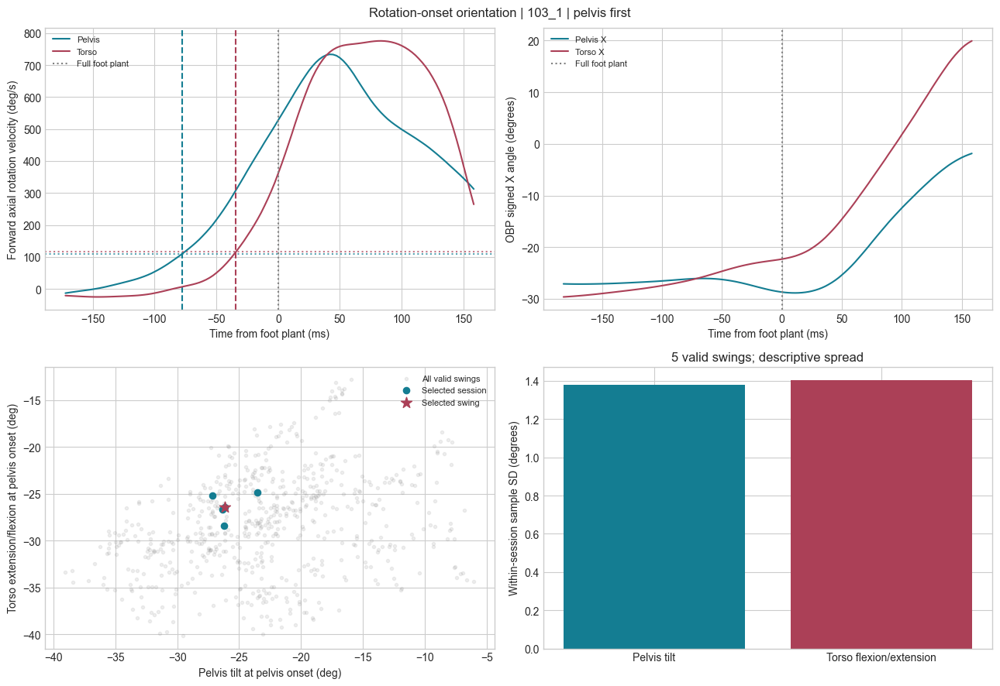

,snapshot,time_from_plant_ms,pelvis_angle_x,pelvis_angle_y,pelvis_angle_z,torso_angle_x,torso_angle_y,torso_angle_z
0,pre_onset,-87.53,-26.32,3.68,-108.34,-26.92,-14.69,-103.61
1,pelvis_onset,-77.53,-26.15,3.55,-107.20,-26.43,-14.30,-103.79
2,torso_onset,-34.08,-26.90,2.99,-97.44,-23.65,-10.48,-103.45


In [6]:
eligible = profile.loc[profile.eligible]
if SELECTED_SWING is None:
    pool = common
    if not eligible.empty:
        p = eligible.iloc[0]
        pool = common.loc[np.logical_and.reduce([common[c].eq(p[c]) for c in GROUP])]
    z = pool[['pelvis_onset__pelvis_angle_x','pelvis_onset__torso_angle_x']]
    scale = z.std().replace(0,1).fillna(1)
    selected_key = pool.loc[((z-z.median())/scale).pow(2).sum(axis=1).idxmin(),'session_swing']
else:
    selected_key = str(SELECTED_SWING)
if selected_key not in reference.index:
    raise ValueError('SELECTED_SWING must have a detected pelvis onset.')
selected,trace = extract(selected_key)
fig,axes = plt.subplots(2,2,figsize=(13,9))
ms = 1000*(trace['time']-selected['fp_100_time'])
for j,(s,color) in enumerate([('pelvis','#147d92'),('torso','#ab4057')]):
    axes[0,0].plot(ms,trace['rates'][:,j],color=color,label=s.title())
    axes[0,0].axhline(selected[s+'_threshold_dps'],color=color,ls=':',alpha=.7)
    if np.isfinite(selected[s+'_onset_s']):
        axes[0,0].axvline(1000*(selected[s+'_onset_s']-selected['fp_100_time']),color=color,ls='--')
    axes[0,1].plot(1000*(trace['angle_time']-selected['fp_100_time']),trace['angles'][:,CHANNELS.index(s+'_angle_x')],color=color,label=s.title()+' X')
for ax in axes[0]:
    ax.axvline(0,color='gray',ls=':',label='Full foot plant')
    ax.set_xlabel('Time from foot plant (ms)');ax.legend(fontsize=8)
axes[0,0].set_ylabel('Forward axial rotation velocity (deg/s)')
axes[0,1].set_ylabel('OBP signed X angle (degrees)')
pc = 'pelvis_onset__pelvis_angle_x';tc='pelvis_onset__torso_angle_x'
own = common.loc[np.logical_and.reduce([common[c].eq(selected[c]) for c in GROUP])]
axes[1,0].scatter(common[pc],common[tc],s=9,alpha=.12,color='gray',label='All valid swings')
axes[1,0].scatter(own[pc],own[tc],s=35,color='#147d92',label='Selected session')
axes[1,0].scatter(selected[pc],selected[tc],s=110,marker='*',color='#ab4057',label='Selected swing')
axes[1,0].set(xlabel='Pelvis tilt at pelvis onset (deg)',ylabel='Torso extension/flexion at pelvis onset (deg)')
axes[1,0].legend(fontsize=8)
measures = own[[pc,tc]].std(ddof=1)
axes[1,1].bar(['Pelvis tilt','Torso flexion/extension'],measures,color=['#147d92','#ab4057'])
axes[1,1].set(ylabel='Within-session sample SD (degrees)',title=f'{len(own)} valid swings; descriptive spread')
fig.suptitle(f'Rotation-onset orientation | {selected_key} | {selected["onset_order"]}')
fig.tight_layout();fig.savefig(FIG/'selected_swing_and_profile.png',dpi=160,bbox_inches='tight');plt.show()
snapshot_table = pd.DataFrame([{'snapshot':label,'time_from_plant_ms':1000*(selected[label+'_snapshot_s']-selected['fp_100_time']),
                               **{c:selected[label+'__'+c] for c in CHANNELS}} for label in ('pre_onset','pelvis_onset','torso_onset')])
display(snapshot_table.round(2))
snapshot_table.to_csv(OUT/'selected_swing_snapshots.csv',index=False)

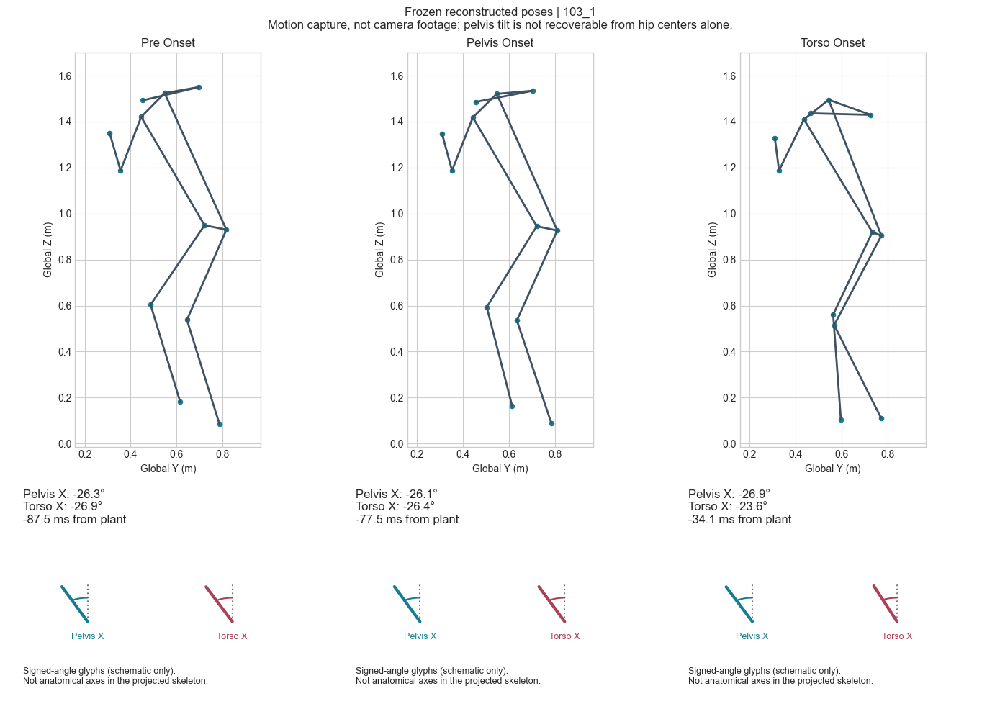

In [7]:
pose_status = 'disabled'
if MAKE_POSE:
    try:
        nodes = ['left_hip','right_hip','lsjc','rsjc','lejc','rejc','lwjc','rwjc','lkjc','rkjc','lajc','rajc']
        cols = ['session_swing','time']+EVENTS+[n+'_'+a for n in nodes for a in 'xyz']
        chunks = pd.read_csv(ensure_signal('landmarks'),usecols=cols,dtype={'session_swing':str},chunksize=100000)
        lm = pd.concat([c.loc[c.session_swing.eq(selected_key)] for c in chunks],ignore_index=True).sort_values('time')
        check_keys(lm,'selected landmarks',['session_swing','time'])
        le = event_values(lm)
        if any(abs(le[c]-selected[c])>1e-4 for c in EVENTS):
            raise ValueError('landmark event disagreement')
        valid_times = [selected[k+'_snapshot_s'] for k in ('pre_onset','pelvis_onset','torso_onset') if np.isfinite(selected[k+'_snapshot_s'])]
        lt,coords = window(lm,[n+'_'+a for n in nodes for a in 'xyz'],min(valid_times)-.010,max(valid_times)+.010)
        poses = {}
        for label in ('pre_onset','pelvis_onset','torso_onset'):
            when = selected[label+'_snapshot_s']
            if np.isfinite(when):
                poses[label] = np.array([np.interp(when,lt,coords[:,j]) for j in range(coords.shape[1])]).reshape(len(nodes),3)
        edges = [('left_hip','right_hip'),('lsjc','rsjc'),('left_hip','lsjc'),('right_hip','rsjc'),('lsjc','lejc'),('lejc','lwjc'),('rsjc','rejc'),('rejc','rwjc'),('left_hip','lkjc'),('lkjc','lajc'),('right_hip','rkjc'),('rkjc','rajc')]
        fig,axes = plt.subplots(2,3,figsize=(14,10),gridspec_kw={'height_ratios':[2,1.1]})
        bound = np.concatenate(list(poses.values()))
        for j,label in enumerate(('pre_onset','pelvis_onset','torso_onset')):
            ax,card = axes[:,j]
            if label not in poses:
                ax.text(.5,.5,'Onset unavailable',ha='center');ax.axis('off');card.axis('off');continue
            p = poses[label]
            for n1,n2 in edges:
                pair = p[[nodes.index(n1),nodes.index(n2)]]
                ax.plot(pair[:,1],pair[:,2],color='#3e5264',lw=2)
            ax.scatter(p[:,1],p[:,2],s=20,color='#147d92')
            ax.set(xlim=(bound[:,1].min()-.15,bound[:,1].max()+.15),ylim=(bound[:,2].min()-.1,bound[:,2].max()+.15),
                   xlabel='Global Y (m)',ylabel='Global Z (m)',title=label.replace('_',' ').title())
            ax.set_aspect('equal')
            card.axis('off')
            text = '\n'.join([f'{s.title()} X: {selected[label+"__"+s+"_angle_x"]:+.1f}°' for s in ('pelvis','torso')])
            text += '\n'+f'{1000*(selected[label+"_snapshot_s"]-selected["fp_100_time"]):+.1f} ms from plant'
            card.text(.05,.98,text,va='top',fontsize=12,transform=card.transAxes)
            for s,cx,color in [('pelvis',.25,'#147d92'),('torso',.70,'#ab4057')]:
                value = selected[label+'__'+s+'_angle_x']
                center = np.array([cx,.37]);radius=.18
                theta = np.deg2rad(value)
                reference_tip = center+np.array([0,radius])
                tip = center+radius*np.array([np.sin(theta),np.cos(theta)])
                card.plot([center[0],reference_tip[0]],[center[1],reference_tip[1]],ls=':',color='gray',transform=card.transAxes)
                card.plot([center[0],tip[0]],[center[1],tip[1]],lw=3,color=color,transform=card.transAxes)
                arc = np.linspace(0,theta,40)
                card.plot(center[0]+.11*np.sin(arc),center[1]+.11*np.cos(arc),color=color,transform=card.transAxes)
                card.text(cx,.29,s.title()+' X',ha='center',fontsize=9,color=color,transform=card.transAxes)
            card.text(.05,.16,'Signed-angle glyphs (schematic only).\nNot anatomical axes in the projected skeleton.',va='top',fontsize=9,transform=card.transAxes)
        fig.suptitle(f'Frozen reconstructed poses | {selected_key}\nMotion capture, not camera footage; pelvis tilt is not recoverable from hip centers alone.')
        fig.tight_layout();fig.savefig(FIG/'selected_frozen_poses.png',dpi=150,bbox_inches='tight');plt.show()
        pose_status = 'created'
    except (OSError,ValueError,KeyError) as exc:
        pose_status = str(exc)
        print('Optional pose unavailable:',exc)
        print('Angle features, audits and profiles remain available.')

Saved report: c:\Users\brend\Documents\GitHub\baseball-biomechanics-analysis\results\rotation_onset_orientation\rotation_onset_orientation.html
Saved feature tables, exclusions, profiles, paired sensitivities and input hashes in c:\Users\brend\Documents\GitHub\baseball-biomechanics-analysis\results\rotation_onset_orientation


setting,processed,detected_pelvis,paired_swings,median_absolute_onset_shift_ms,p90_absolute_onset_shift_ms,pelvis_median_absolute_angle_shift_deg,pelvis_p90_absolute_angle_shift_deg,torso_median_absolute_angle_shift_deg,torso_p90_absolute_angle_shift_deg
primary,642,642,642,0.00,0.00,0.00,0.00,0.00,0.00
floor_40,642,642,642,0.00,0.00,0.00,0.00,0.00,0.00
floor_80,642,642,642,0.00,0.00,0.00,0.00,0.00,0.00
fraction_10,642,639,639,8.08,13.57,0.26,0.65,0.16,0.45
fraction_20,642,642,642,6.78,10.85,0.25,0.61,0.15,0.40
sustain_15ms,642,642,642,0.00,0.00,0.00,0.00,0.00,0.00
lookback_100ms,642,611,611,0.00,0.00,0.00,0.00,0.00,0.00
lookback_200ms,642,642,642,0.00,0.00,0.00,0.00,0.00,0.00

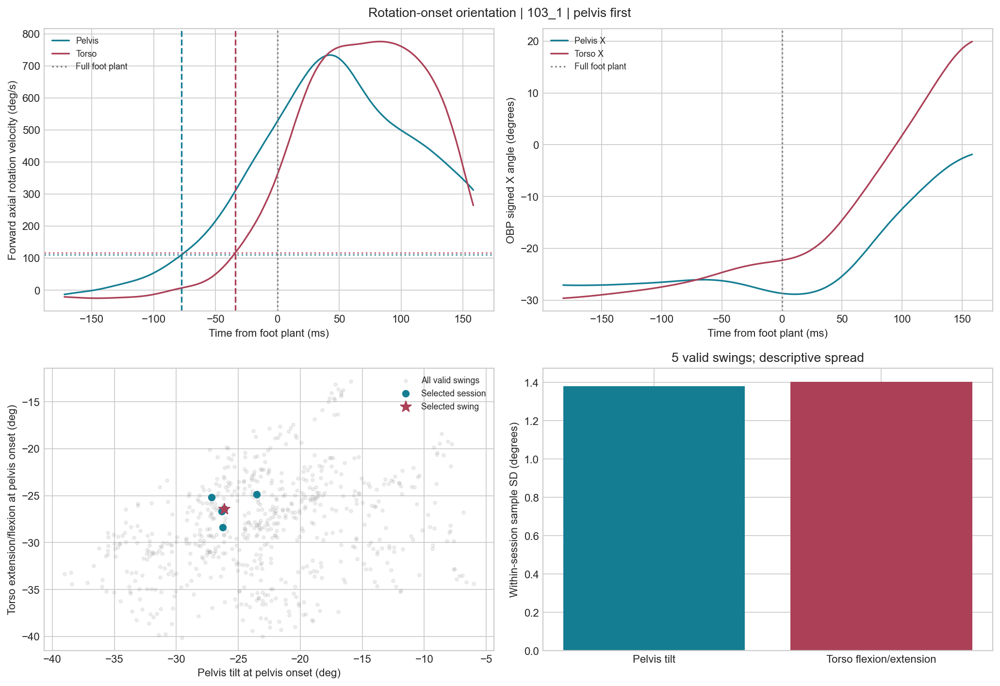
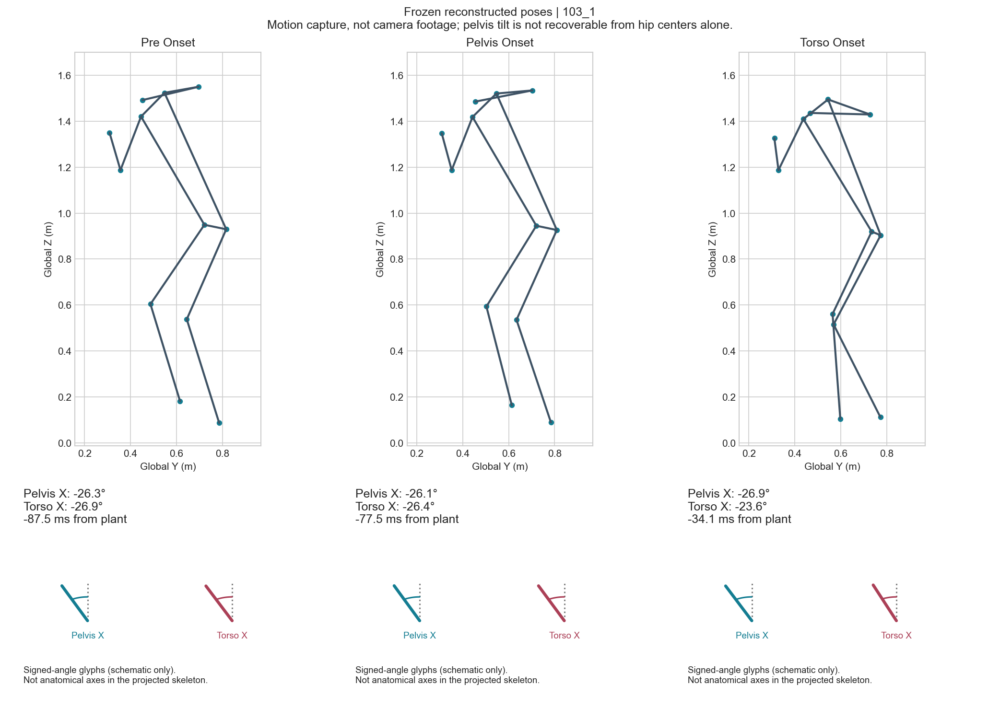

In [8]:
plot_records = common[['session_swing']+GROUP+[pc,tc]+OUTCOMES].copy()
plot_records['profile_id'] = plot_records[GROUP].astype(str).agg(' / '.join,axis=1)
plot_records = plot_records.rename(columns={pc:'pelvis',tc:'torso'})
records = json.loads(plot_records.to_json(orient='records'))
options = ''.join('<option value="'+html.escape(r.profile_id,quote=True)+'">'+html.escape(r.profile_id)+f' ({r.n_swings} swings'+('' if r.eligible else '; below reporting minimum')+')</option>' for r in profile.itertuples())
def embed_image(path):
    return '<img style="width:100%;max-width:1200px" src="data:image/png;base64,'+base64.b64encode(path.read_bytes()).decode()+'">' if path.exists() else ''
report = """<!doctype html><html><head><meta charset="utf-8"><title>Rotation-onset orientation</title>
<style>body{font:16px system-ui;max-width:1200px;margin:30px auto;padding:20px;color:#203446;background:#f7f9fb}select{padding:9px;max-width:100%}svg{background:white;width:100%;max-width:900px}table{border-collapse:collapse}td,th{padding:8px;border-bottom:1px solid #ccd5de}p{line-height:1.5}</style></head><body>
<h1>Pelvis and torso orientation at rotation onset</h1>
<p>Both angles below are measured at the same detected pelvis onset. Pelvis X: posterior (+)/anterior (−) tilt. Torso X: extension (+)/flexion (−). No ideal-position grade is calculated.</p>
<label>Hitter / session / batting side <select id="profile">OPTIONS</select></label>
<p id="summary"></p><svg id="scatter" viewBox="0 0 900 510" role="img" aria-label="Pelvis tilt versus torso flexion at pelvis onset"></svg>
<p>Dots are individual swings; the red cross is the session mean. Spread is within this session, not long-term reliability. Hover over a dot for the swing ID and angles.</p>
<div id="reps"></div><h2>Selected swing diagnostic</h2>DIAGNOSTIC<h2>Frozen reconstructed poses</h2>POSE
<h2>Onset sensitivity</h2>SENSITIVITY
<h2>Interpretation</h2><p>Onsets use sustained forward-rotation velocity crossings. The threshold depends on the subsequent pre-contact peak, so this is retrospective. Left-censored and absent detections are reported separately. The pre-onset pose is 10 ms before the earlier detected onset only when both segment onsets are available. It is not proof of zero prior motion.</p>
<p>Profiles need MINIMUM swings for primary reporting. Low-count profiles remain visible for inspection. Optional bat speed, attack angle and exit velocity are context only; no performance association or coaching prescription is fitted. This study cannot establish a permanent hitter identity.</p>
<p>Data: <a href="https://github.com/drivelineresearch/openbiomechanics">Driveline OpenBiomechanics Dataset v1</a>. Review the upstream data license before sharing individual data or derived reports.</p>
<script>const data=DATA, minimum=MINIMUM;
const select=document.getElementById('profile'), svg=document.getElementById('scatter');
function draw(){const rows=data.filter(r=>r.profile_id===select.value);if(!rows.length)return;
const mean=k=>rows.reduce((a,r)=>a+r[k],0)/rows.length;
const sd=k=>rows.length>1?Math.sqrt(rows.reduce((a,r)=>a+(r[k]-mean(k))**2,0)/(rows.length-1)):null;
let xs=data.map(r=>r.pelvis),ys=data.map(r=>r.torso),xmin=Math.min(...xs)-3,xmax=Math.max(...xs)+3,ymin=Math.min(...ys)-3,ymax=Math.max(...ys)+3;
const X=x=>85+(x-xmin)/(xmax-xmin)*740,Y=y=>420-(y-ymin)/(ymax-ymin)*370;
let s='<line x1="85" y1="420" x2="825" y2="420" stroke="#526578"/><line x1="85" y1="50" x2="85" y2="420" stroke="#526578"/>';
for(let i=0;i<=5;i++){let x=xmin+(xmax-xmin)*i/5,y=ymin+(ymax-ymin)*i/5;s+=`<text x="${X(x)}" y="445" text-anchor="middle">${x.toFixed(0)}</text><text x="70" y="${Y(y)+5}" text-anchor="end">${y.toFixed(0)}</text>`;}
for(const r of rows){s+=`<circle cx="${X(r.pelvis)}" cy="${Y(r.torso)}" r="6" fill="#147d92" opacity=".7"><title>${r.session_swing}: pelvis ${r.pelvis.toFixed(2)}°, torso ${r.torso.toFixed(2)}°</title></circle>`;}
let mx=X(mean('pelvis')),my=Y(mean('torso'));s+=`<path d="M${mx-8},${my}h16 M${mx},${my-8}v16" stroke="#ab4057" stroke-width="3"/><text x="450" y="485" text-anchor="middle">Pelvis tilt at pelvis onset (degrees)</text><text transform="translate(22 245) rotate(-90)" text-anchor="middle">Torso extension/flexion at pelvis onset (degrees)</text>`;
svg.innerHTML=s;document.getElementById('summary').textContent=`${rows.length} valid swings | Pelvis mean ${mean('pelvis').toFixed(1)}°, SD ${sd('pelvis')===null?'unavailable':sd('pelvis').toFixed(1)+'°'} | Torso mean ${mean('torso').toFixed(1)}°, SD ${sd('torso')===null?'unavailable':sd('torso').toFixed(1)+'°'}${rows.length<minimum?' | Below primary reporting minimum':''}`;
let table='<table><tr><th>Swing</th><th>Pelvis tilt (°)</th><th>Torso extension/flexion (°)</th></tr>';
for(const r of rows)table+=`<tr><td>${r.session_swing}</td><td>${r.pelvis.toFixed(2)}</td><td>${r.torso.toFixed(2)}</td></tr>`;
document.getElementById('reps').innerHTML=table+'</table>';}
select.addEventListener('change',draw);draw();</script></body></html>"""
report = report.replace('OPTIONS',options).replace('DIAGNOSTIC',embed_image(FIG/'selected_swing_and_profile.png')).replace('POSE',embed_image(FIG/'selected_frozen_poses.png') if pose_status=='created' else '<p>Optional pose unavailable or disabled.</p>')
report = report.replace('SENSITIVITY',sensitivity.round(2).to_html(index=False)).replace('DATA',json.dumps(records,allow_nan=False).replace('</','<\\/')).replace('MINIMUM',str(MIN_VALID_SWINGS))
(OUT/'rotation_onset_orientation.html').write_text(report,encoding='utf-8')
manifest = {'study':'19_rotation_onset_orientation','dataset':'OpenBiomechanics Dataset v1','python':platform.python_version(),
            'packages':{'numpy':np.__version__,'pandas':pd.__version__},
            'settings':{'lookback_s':LOOKBACK_S,'floor_dps':FLOOR_DPS,'peak_fraction':PEAK_FRACTION,'sustain_s':SUSTAIN_S,'pre_onset_s':PRE_ONSET_S,'minimum_swings':MIN_VALID_SWINGS},
            'sensitivity':configs,'archive_expected_sha256':HASHES,
            'input_sha256':{n:sha256(RAW/n) for n in ('joint_angles.csv','joint_velos.csv','metadata.csv','poi_metrics.csv','landmarks.csv') if (RAW/n).exists()},
            'processed_trials':len(features),'detected_pelvis_trials':len(common),'eligible_profiles':int(profile.eligible.sum()),
            'selected_swing':selected_key,'pose_status':pose_status,'performance_model_fitted':False,
            'angle_conventions':'OBP processed signs retained; X angles are not interchangeable anatomical quantities',
            'onset_definition':'first sustained crossing of max(absolute floor, fraction of positive precontact peak); left-boundary runs censored; interpolated crossing',
            'limitations':['retrospective onset and processed signals','single-session repeatability','no causal or ideal posture claim','skeleton projection does not define processed pelvis angle']}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Saved report:',OUT/'rotation_onset_orientation.html')
print('Saved feature tables, exclusions, profiles, paired sensitivities and input hashes in',OUT)
display(HTML(report))

In [9]:
AUDIT = OUT / 'profile_stability_audit'
AUDIT_FIG = FIG / 'profile_stability_audit'
for folder in (AUDIT,AUDIT_FIG):
    folder.mkdir(parents=True,exist_ok=True)
FOCUS_PROFILE = ('000076','000190','R')
AUDIT_CHANNELS = ['pelvis_onset__'+c for c in CHANNELS]

def omission_audit(frame, columns, minimum):
    records,summaries = [],[]
    for identity,g in frame.groupby(GROUP,sort=False):
        if len(g)<minimum:
            continue
        pid = ' / '.join(map(str,identity))
        values = g[columns].to_numpy(float)
        if not np.isfinite(values).all() or len(values)<3:
            raise ValueError('Omission audit requires finite angles and at least three swings')
        mean,sd,median = values.mean(axis=0),values.std(axis=0,ddof=1),np.median(values,axis=0)
        summary = {**dict(zip(GROUP,identity)),'profile_id':pid,'n_swings':len(g)}
        profile_rows = []
        for i,key in enumerate(g.session_swing):
            remaining = np.delete(values,i,axis=0)
            reduced_mean,reduced_sd = remaining.mean(axis=0),remaining.std(axis=0,ddof=1)
            row = {'profile_id':pid,'omitted_swing':str(key),'n_original':len(g),'n_remaining':len(remaining),
                   'remaining_meets_primary_minimum':len(remaining)>=minimum}
            for j,c in enumerate(columns):
                row[c+'__original_mean'] = mean[j]
                row[c+'__original_sd'] = sd[j]
                row[c+'__remaining_mean'] = reduced_mean[j]
                row[c+'__remaining_sd'] = reduced_sd[j]
                row[c+'__mean_shift'] = reduced_mean[j]-mean[j]
                row[c+'__sd_change'] = reduced_sd[j]-sd[j]
            records.append(row);profile_rows.append(row)
        omissions = pd.DataFrame(profile_rows)
        for j,c in enumerate(columns):
            summary[c+'__mean'] = mean[j]
            summary[c+'__sd'] = sd[j]
            summary[c+'__median'] = median[j]
            summary[c+'__mean_minus_median'] = mean[j]-median[j]
            summary[c+'__max_absolute_mean_shift'] = omissions[c+'__mean_shift'].abs().max()
            summary[c+'__max_sd_reduction'] = -min(0.,omissions[c+'__sd_change'].min())
            summary[c+'__max_absolute_sd_change'] = omissions[c+'__sd_change'].abs().max()
            idx = omissions[c+'__mean_shift'].abs().idxmax()
            summary[c+'__most_mean_influential_swing'] = omissions.loc[idx,'omitted_swing']
        summaries.append(summary)
    return pd.DataFrame(records),pd.DataFrame(summaries)

toy = pd.DataFrame({'user':['a']*5,'session':['b']*5,'hitter_side':['R']*5,
                    'session_swing':list('12345'),'angle':[0.,0.,0.,0.,10.]})
test_loo,test_summary = omission_audit(toy,['angle'],5)
last = test_loo.loc[test_loo.omitted_swing.eq('5')].iloc[0]
assert np.isclose(last.angle__remaining_mean,0) and np.isclose(last.angle__mean_shift,-2)
assert np.isclose(last.angle__remaining_sd,0) and not last.remaining_meets_primary_minimum
assert np.isclose(test_summary.iloc[0].angle__max_absolute_mean_shift,2)
toy['angle']=3.
constant_loo,_ = omission_audit(toy,['angle'],5)
assert np.allclose(constant_loo.angle__mean_shift,0) and np.allclose(constant_loo.angle__sd_change,0)

omissions,stability = omission_audit(common,AUDIT_CHANNELS,MIN_VALID_SWINGS)
if stability.empty:
    raise ValueError('No eligible profiles for the omission audit')
pc = 'pelvis_onset__pelvis_angle_x'
tc = 'pelvis_onset__torso_angle_x'
focus_mask = np.logical_and.reduce([common[c].eq(v) for c,v in zip(GROUP,FOCUS_PROFILE)])
focus = common.loc[focus_mask].copy()
if len(focus)<MIN_VALID_SWINGS:
    highest = stability.sort_values(pc+'__sd',ascending=False).iloc[0]
    FOCUS_PROFILE = tuple(highest[c] for c in GROUP)
    focus = common.loc[np.logical_and.reduce([common[c].eq(v) for c,v in zip(GROUP,FOCUS_PROFILE)])].copy()
focus_id = ' / '.join(FOCUS_PROFILE)
focus_loo = omissions.loc[omissions.profile_id.eq(focus_id)].copy()
stability['pelvis_mean_influence_rank'] = stability[pc+'__max_absolute_mean_shift'].rank(method='min',ascending=False).astype(int)
stability['pelvis_sd_rank'] = stability[pc+'__sd'].rank(method='min',ascending=False).astype(int)
omissions.to_csv(AUDIT/'leave_one_swing_out.csv',index=False)
stability.to_csv(AUDIT/'profile_stability.csv',index=False)
focus_loo.to_csv(AUDIT/'focused_session_omissions.csv',index=False)
metrics = []
for name,c in [('pelvis_tilt',pc),('torso_flexion_extension',tc)]:
    for measure in ('sd','max_absolute_mean_shift','max_sd_reduction','max_absolute_sd_change'):
        values = stability[c+'__'+measure]
        metrics.append({'channel':name,'measure':measure,'profiles':len(values),
                        'median_deg':values.median(),'p90_deg':values.quantile(.9),'maximum_deg':values.max()})
audit_summary = pd.DataFrame(metrics)
audit_summary.to_csv(AUDIT/'cohort_summary.csv',index=False)
display(audit_summary.round(3))
print('Focused profile:',focus_id,'|',len(focus),'swings')
print('Primary measurements and eligibility are preserved. Every omission is a diagnostic, not an exclusion.')
print('A five-swing profile leaves four after omission; that diagnostic does not meet the primary reporting minimum.')

,channel,measure,profiles,median_deg,p90_deg,maximum_deg
0,pelvis_tilt,sd,87,1.041,1.744,6.725
1,pelvis_tilt,max_absolute_mean_shift,87,0.282,0.507,2.203
2,pelvis_tilt,max_sd_reduction,87,0.220,0.517,3.989
3,pelvis_tilt,max_absolute_sd_change,87,0.231,0.517,3.989
4,torso_flexion_extension,sd,87,0.898,1.468,2.660
5,torso_flexion_extension,max_absolute_mean_shift,87,0.233,0.474,0.621
6,torso_flexion_extension,max_sd_reduction,87,0.208,0.509,1.006
7,torso_flexion_extension,max_absolute_sd_change,87,0.208,0.509,1.006


Focused profile: 000076 / 000190 / R | 8 swings
Primary measurements and eligibility are preserved. Every omission is a diagnostic, not an exclusion.
A five-swing profile leaves four after omission; that diagnostic does not meet the primary reporting minimum.


In [10]:
def peak_episode_onset(t,rate,threshold,sustain=SUSTAIN_S):
    t,rate = np.asarray(t,float),np.asarray(rate,float)
    if len(t)!=len(rate) or len(t)<3 or not np.isfinite(rate).all() or np.any(np.diff(t)<=0):
        raise ValueError('Invalid episode inputs')
    peak = int(np.argmax(rate))
    if rate[peak]<threshold:
        return {'state':'not_detected','time':np.nan,'episode_start_s':np.nan,'episode_end_s':np.nan,'qualified_runs':0}
    positive = rate>0
    left=peak
    while left>0 and positive[left-1]:
        left-=1
    right=peak
    while right<len(rate)-1 and positive[right+1]:
        right+=1
    above = rate>=threshold
    starts = np.flatnonzero(above & ~np.r_[False,above[:-1]])
    ends = np.flatnonzero(above & ~np.r_[above[1:],False])
    qualified = [(a,b) for a,b in zip(starts,ends) if t[b]-t[a]>=sustain-1e-10]
    candidates = [(a,b) for a,b in qualified if left<=a<=peak and b<=right]
    out = {'state':'not_detected','time':np.nan,'episode_start_s':float(t[left]),
           'episode_end_s':float(t[right]),'qualified_runs':len(qualified)}
    if candidates:
        a,b = candidates[0]
        if a==0:
            out['state']='left_censored'
        else:
            out['state']='detected'
            out['time']=float(t[a-1]+(threshold-rate[a-1])*(t[a]-t[a-1])/(rate[a]-rate[a-1]))
    return out

test_t = np.arange(100)/360
test_rate = np.zeros(100)
test_rate[8:18]=100
test_rate[40:75]=200
first = onset(test_t,test_rate,floor=60,fraction=0)
main = peak_episode_onset(test_t,test_rate,60)
assert main['qualified_runs']==2 and main['time']>first['time']+.05
same = peak_episode_onset(test_t,np.full(100,200.),60)
assert same['state']=='left_censored' and not np.isfinite(same['time'])
assert np.isclose(peak_episode_onset(test_t,np.where(test_t<.1,0.,200.),60)['time'],onset(test_t,np.where(test_t<.1,0.,200.),floor=60,fraction=0)['time'])

episode_rows = []
for key in common.session_swing:
    row,trace = extract(key)
    for j,s in enumerate(('pelvis','torso')):
        alternative = peak_episode_onset(trace['time'],trace['rates'][:,j],row[s+'_threshold_dps'])
        when = alternative['time']
        primary_time = row[s+'_onset_s']
        record = {'session_swing':key,**{c:row[c] for c in GROUP},'segment':s,
                  'primary_state':row[s+'_state'],'primary_onset_s':primary_time,
                  'peak_episode_state':alternative['state'],'peak_episode_onset_s':when,
                  'episode_start_s':alternative['episode_start_s'],'episode_end_s':alternative['episode_end_s'],
                  'qualified_threshold_runs':alternative['qualified_runs'],
                  'onset_shift_ms':1000*(when-primary_time) if np.isfinite([when,primary_time]).all() else np.nan}
        record['different_by_more_than_one_sample'] = abs(record['onset_shift_ms'])>1000/360+1e-7 if np.isfinite(record['onset_shift_ms']) else False
        for c in ('pelvis_angle_x','torso_angle_x'):
            alt_angle = float(np.interp(when,trace['angle_time'],trace['angles'][:,CHANNELS.index(c)])) if np.isfinite(when) else np.nan
            record[c+'__primary_common'] = row['pelvis_onset__'+c]
            record[c+'__at_alternative_segment_onset'] = alt_angle
            record[c+'__change_from_primary_common'] = alt_angle-row['pelvis_onset__'+c] if s=='pelvis' else np.nan
        episode_rows.append(record)
episodes = pd.DataFrame(episode_rows)
episodes.to_csv(AUDIT/'peak_episode_comparison.csv',index=False)
focus_episodes = episodes.loc[np.logical_and.reduce([episodes[c].eq(v) for c,v in zip(GROUP,FOCUS_PROFILE)])]
focus_pelvis = focus_episodes.loc[focus_episodes.segment.eq('pelvis')].set_index('session_swing')
focus_table = focus[['session_swing',pc,tc,'pelvis_onset_s','torso_onset_s','onset_lag_ms']].copy()
focus_table['pelvis_onset_ms_from_contact'] = 1000*(focus.pelvis_onset_s-focus.contact_time)
for col in ('peak_episode_state','qualified_threshold_runs','onset_shift_ms','different_by_more_than_one_sample',
            'pelvis_angle_x__change_from_primary_common','torso_angle_x__change_from_primary_common'):
    focus_table[col] = focus_table.session_swing.map(focus_pelvis[col])
focus_table.to_csv(AUDIT/'focused_session_episode_review.csv',index=False)
episode_summary = episodes.groupby(['segment','primary_state','peak_episode_state']).agg(
    swings=('session_swing','size'),changed_more_than_one_sample=('different_by_more_than_one_sample','sum'),
    median_absolute_onset_shift_ms=('onset_shift_ms',lambda v:v.abs().median() if v.notna().any() else np.nan),
    maximum_absolute_onset_shift_ms=('onset_shift_ms',lambda v:v.abs().max() if v.notna().any() else np.nan)).reset_index()
episode_summary.to_csv(AUDIT/'peak_episode_summary.csv',index=False)
display(episode_summary.round(3))
display(focus_table.drop(columns=['pelvis_onset_s','torso_onset_s']).round(3))
print('Alternative definition: first sustained crossing within the positive-velocity episode containing the precontact peak.')
print('The same threshold is retained. The alternative is an episode diagnostic, not a corrected ground truth.')
print('One-sample difference flags reflect temporal resolution; they are not mechanical-quality cutoffs.')

,segment,primary_state,peak_episode_state,swings,changed_more_than_one_sample,median_absolute_onset_shift_ms,maximum_absolute_onset_shift_ms
0,pelvis,detected,detected,642,0,0.0,0.000
1,torso,detected,detected,641,14,0.0,119.126
2,torso,left_censored,detected,1,0,NaN,NaN


,session_swing,pelvis_onset__pelvis_angle_x,pelvis_onset__torso_angle_x,onset_lag_ms,pelvis_onset_ms_from_contact,peak_episode_state,qualified_threshold_runs,onset_shift_ms,different_by_more_than_one_sample,pelvis_angle_x__change_from_primary_common,torso_angle_x__change_from_primary_common
117,190_1,-14.368,-32.811,38.777,-211.991,detected,1,0.0,False,0.0,0.0
118,190_2,-14.723,-32.805,41.222,-214.627,detected,1,0.0,False,0.0,0.0
119,190_3,-15.426,-31.726,44.336,-227.463,detected,1,0.0,False,0.0,0.0
120,190_4,-13.120,-28.421,37.615,-211.867,detected,1,0.0,False,0.0,0.0
121,190_5,-18.953,-27.984,42.804,-220.776,detected,1,0.0,False,0.0,0.0
122,190_6,-34.076,-26.469,30.425,-208.056,detected,1,0.0,False,0.0,0.0
123,190_7,-18.067,-27.205,47.910,-226.175,detected,1,0.0,False,0.0,0.0
124,190_8,-20.523,-27.271,34.255,-210.571,detected,1,0.0,False,0.0,0.0


Alternative definition: first sustained crossing within the positive-velocity episode containing the precontact peak.
The same threshold is retained. The alternative is an episode diagnostic, not a corrected ground truth.
One-sample difference flags reflect temporal resolution; they are not mechanical-quality cutoffs.


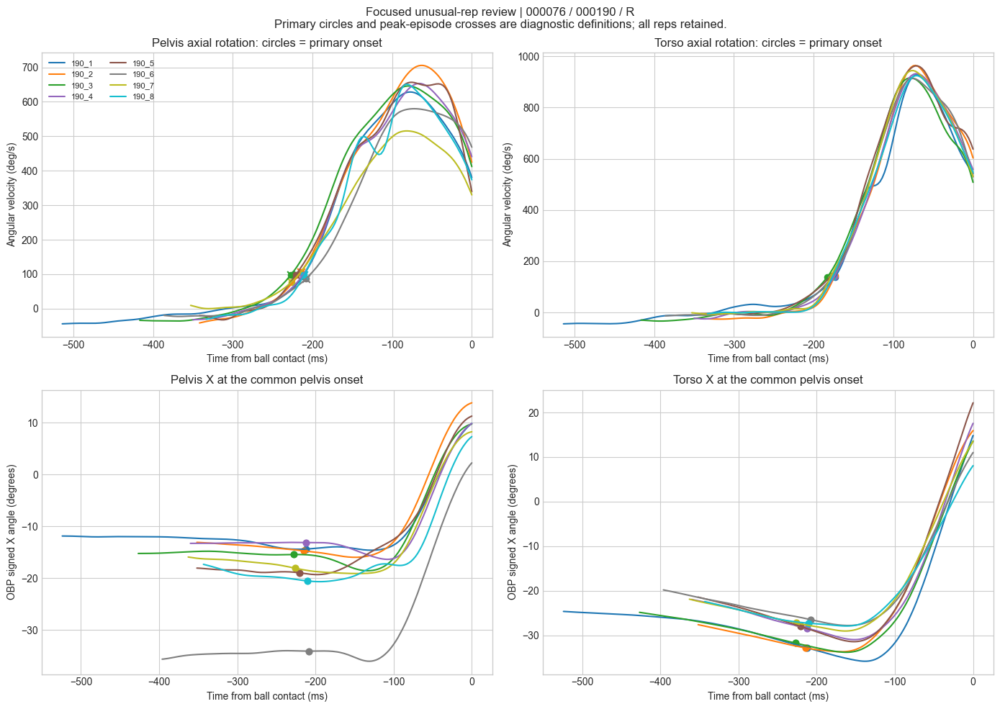

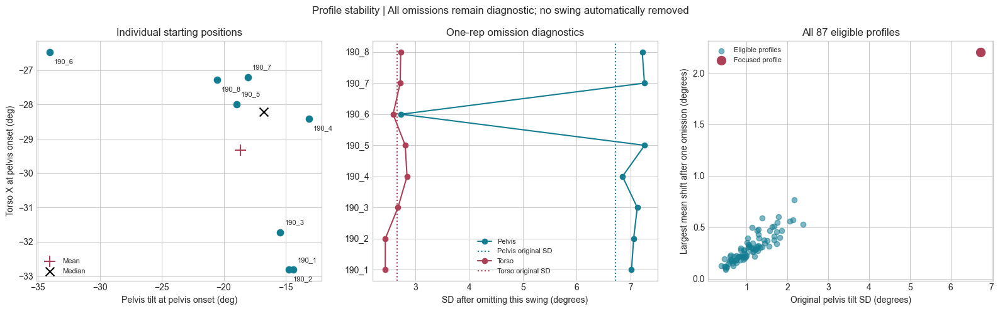

,profile_id,n_swings,pelvis_onset__pelvis_angle_x__sd,pelvis_onset__pelvis_angle_x__max_absolute_mean_shift,pelvis_onset__pelvis_angle_x__max_sd_reduction,pelvis_onset__pelvis_angle_x__most_mean_influential_swing
16,000076 / 000190 / R,8,6.725,2.203,3.989,190_6
80,000163 / 000068 / R,5,2.163,0.768,0.644,68_1
58,000145 / 000042 / R,5,1.782,0.603,0.437,42_1
0,000004 / 000103 / R,5,1.379,0.590,0.914,103_4
6,000051 / 000160 / R,8,2.141,0.570,0.620,160_8
67,000149 / 000047 / R,5,2.062,0.559,0.168,47_1
10,000019 / 000174 / R,6,1.754,0.545,0.481,174_5
72,000193 / 000500 / R,8,2.377,0.528,0.379,500_2
17,000083 / 000199 / R,8,1.664,0.510,0.769,199_2
52,000215 / 000376 / R,7,1.622,0.505,0.616,376_6


,omitted_swing,n_remaining,remaining_meets_primary_minimum,pelvis_onset__pelvis_angle_x__remaining_mean,pelvis_onset__pelvis_angle_x__remaining_sd,pelvis_onset__torso_angle_x__remaining_sd,pelvis_onset__pelvis_angle_x__mean_shift
117,190_1,7,True,-19.270,7.019,2.440,-0.613
118,190_2,7,True,-19.219,7.058,2.441,-0.562
119,190_3,7,True,-19.119,7.126,2.677,-0.462
120,190_4,7,True,-19.448,6.851,2.845,-0.791
121,190_5,7,True,-18.615,7.263,2.811,0.042
122,190_6,7,True,-16.454,2.736,2.586,2.203
123,190_7,7,True,-18.741,7.260,2.718,-0.084
124,190_8,7,True,-18.391,7.218,2.727,0.267


Most SD-influential focused rep: 190_6
Focused pelvis SD: 6.725 degrees; after omitting that rep: 2.736 degrees.
Focused pelvis mean shift after omission: +2.203 degrees.
Primary and peak-episode pelvis onsets agree across all valid common snapshots: True
These checks do not distinguish an actual posture change from a motion-capture/modeling artifact.
Audit complete: 87 profiles; 608 one-swing omissions.
Focused session: 000076 / 000190 / R | all 8 swings retained in the primary profile.
Audit report: c:\Users\brend\Documents\GitHub\baseball-biomechanics-analysis\results\rotation_onset_orientation\profile_stability_audit\profile_stability_audit.html



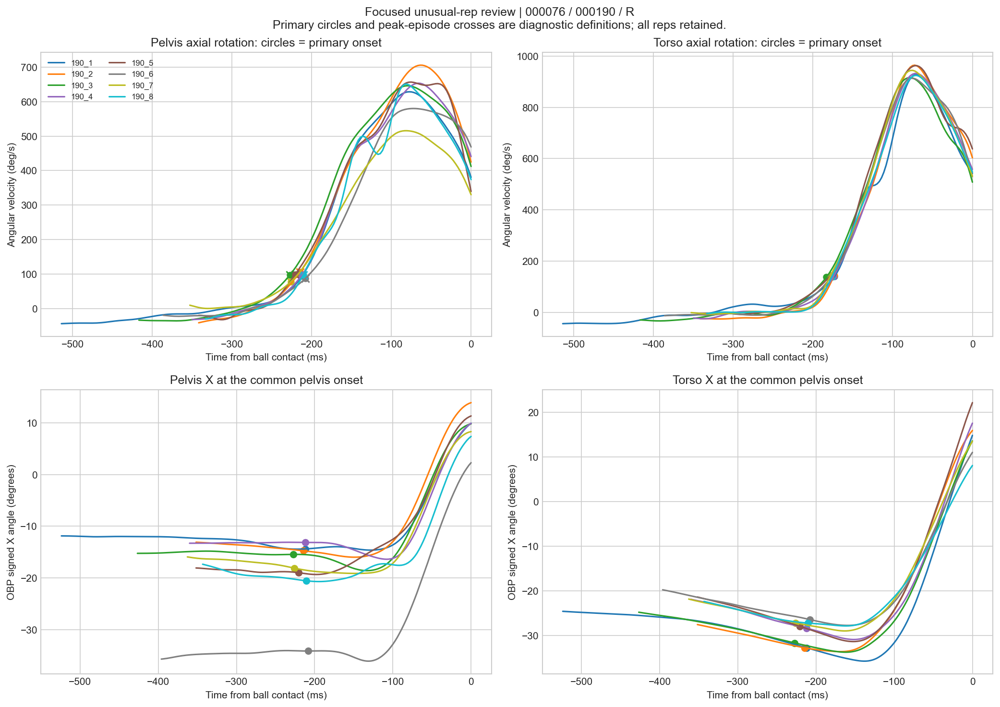
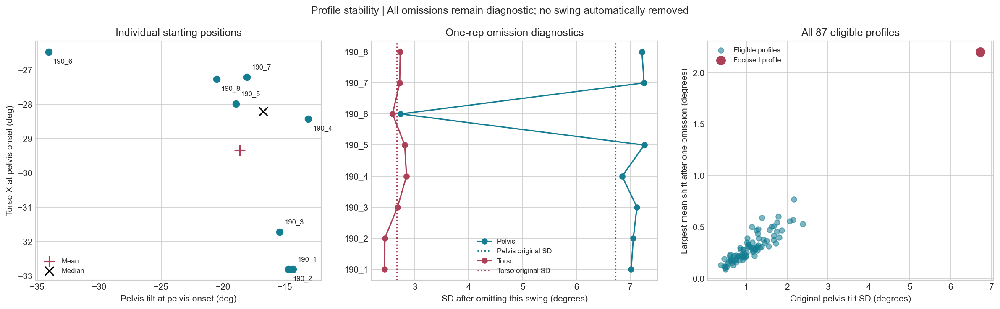

In [11]:
fig,axes = plt.subplots(2,2,figsize=(14,10))
colors = plt.cm.tab10(np.linspace(0,1,len(focus)))
for color,(_,rep) in zip(colors,focus.iterrows()):
    row,tr = extract(rep.session_swing)
    time_ms = 1000*(tr['time']-row['contact_time'])
    angle_ms = 1000*(tr['angle_time']-row['contact_time'])
    for j,s in enumerate(('pelvis','torso')):
        ax = axes[0,j]
        ax.plot(time_ms,tr['rates'][:,j],color=color,label=rep.session_swing)
        onset_ms = 1000*(row[s+'_onset_s']-row['contact_time'])
        if np.isfinite(onset_ms):
            ax.scatter(onset_ms,row[s+'_threshold_dps'],color=color,s=35,marker='o')
        ax.set(title=s.title()+' axial rotation: circles = primary onset',xlabel='Time from ball contact (ms)',ylabel='Angular velocity (deg/s)')
    alt = focus_pelvis.loc[rep.session_swing]
    if np.isfinite(alt.peak_episode_onset_s):
        alt_ms = 1000*(alt.peak_episode_onset_s-row['contact_time'])
        axes[0,0].scatter(alt_ms,row['pelvis_threshold_dps'],marker='x',s=60,color=color)
    for j,s in enumerate(('pelvis','torso')):
        axes[1,j].plot(angle_ms,tr['angles'][:,CHANNELS.index(s+'_angle_x')],color=color)
        axes[1,j].scatter(1000*(row['pelvis_onset_s']-row['contact_time']),row['pelvis_onset__'+s+'_angle_x'],s=40,color=color)
        axes[1,j].set(title=s.title()+' X at the common pelvis onset',xlabel='Time from ball contact (ms)',ylabel='OBP signed X angle (degrees)')
axes[0,0].legend(fontsize=8,ncol=2)
fig.suptitle('Focused unusual-rep review | '+focus_id+'\nPrimary circles and peak-episode crosses are diagnostic definitions; all reps retained.')
fig.tight_layout();fig.savefig(AUDIT_FIG/'focused_rep_timelines.png',dpi=150,bbox_inches='tight');plt.show()

fig,axes = plt.subplots(1,3,figsize=(16,5))
axes[0].scatter(focus[pc],focus[tc],s=55,color='#147d92')
for label_i,rep in enumerate(focus.itertuples()):
    key = rep.session_swing
    point = focus.loc[focus.session_swing.eq(key)].iloc[0]
    axes[0].annotate(key,(point[pc],point[tc]),xytext=(5,9 if label_i%2==0 else -13),textcoords='offset points',fontsize=8)
axes[0].scatter(focus[pc].mean(),focus[tc].mean(),marker='+',s=160,color='#ab4057',label='Mean')
axes[0].scatter(focus[pc].median(),focus[tc].median(),marker='x',s=100,color='black',label='Median')
axes[0].set(xlabel='Pelvis tilt at pelvis onset (deg)',ylabel='Torso X at pelvis onset (deg)',title='Individual starting positions')
axes[0].legend(fontsize=8)
y = np.arange(len(focus_loo))
for c,label,color in [(pc,'Pelvis','#147d92'),(tc,'Torso','#ab4057')]:
    axes[1].plot(focus_loo[c+'__remaining_sd'],y,marker='o',label=label,color=color)
    original = focus[c].std(ddof=1)
    axes[1].axvline(original,color=color,ls=':',label=label+' original SD')
axes[1].set_yticks(y,focus_loo.omitted_swing)
axes[1].set(xlabel='SD after omitting this swing (degrees)',title='One-rep omission diagnostics')
axes[1].legend(fontsize=8)
axes[2].scatter(stability[pc+'__sd'],stability[pc+'__max_absolute_mean_shift'],color='#147d92',alpha=.55,label='Eligible profiles')
f = stability.loc[stability.profile_id.eq(focus_id)].iloc[0]
axes[2].scatter(f[pc+'__sd'],f[pc+'__max_absolute_mean_shift'],s=100,color='#ab4057',label='Focused profile')
axes[2].set(xlabel='Original pelvis tilt SD (degrees)',ylabel='Largest mean shift after one omission (degrees)',title=f'All {len(stability)} eligible profiles')
axes[2].legend(fontsize=8)
fig.suptitle('Profile stability | All omissions remain diagnostic; no swing automatically removed')
fig.tight_layout();fig.savefig(AUDIT_FIG/'profile_omission_influence.png',dpi=150,bbox_inches='tight');plt.show()

top = stability.sort_values(pc+'__max_absolute_mean_shift',ascending=False).head(10)
top_cols = ['profile_id','n_swings',pc+'__sd',pc+'__max_absolute_mean_shift',pc+'__max_sd_reduction',pc+'__most_mean_influential_swing']
display(top[top_cols].round(3))
focus_display_cols = ['omitted_swing','n_remaining','remaining_meets_primary_minimum',pc+'__remaining_mean',pc+'__remaining_sd',tc+'__remaining_sd',pc+'__mean_shift']
display(focus_loo[focus_display_cols].round(3))

audit_section = '<section style="overflow-x:auto"><h2>Unusual-rep and profile-stability audit</h2><p>Focused profile: '+html.escape(focus_id)+'. Primary profiles retain every eligible swing. Omission and peak-episode comparisons are diagnostics, not data cleaning.</p>'
audit_section += '<h3>Cohort influence summary</h3>'+audit_summary.round(3).to_html(index=False)
audit_section += embed_image(AUDIT_FIG/'focused_rep_timelines.png')+embed_image(AUDIT_FIG/'profile_omission_influence.png')
audit_section += '<h3>Focused session: each swing omitted once</h3>'+focus_loo[focus_display_cols].round(3).to_html(index=False)
audit_section += '<h3>Rotation episode comparison</h3>'+episode_summary.round(3).to_html(index=False)
audit_section += '<h3>Profiles with greatest pelvis mean influence</h3>'+top[top_cols].round(3).to_html(index=False)
audit_section += '<p>The alternative detector uses the positive-velocity episode containing the precontact peak and the original threshold. Short sign reversals can split an episode; it is not a validated biological onset. A changed onset does not prove the primary rep is invalid. Omission can reduce sample size below the reporting minimum. This audit does not establish test–retest reliability.</p></section>'
audit_report = '<!doctype html><html><head><meta charset="utf-8"><title>Orientation profile stability audit</title><style>body{font:15px system-ui;max-width:1400px;margin:25px auto;padding:20px;color:#203446}table{display:block;overflow:auto;border-collapse:collapse;font-size:12px}td,th{padding:7px;border-bottom:1px solid #dce3e9}p{line-height:1.5}</style></head><body>'+audit_section+'</body></html>'
(AUDIT/'profile_stability_audit.html').write_text(audit_report,encoding='utf-8')
report = report.replace('<h2>Interpretation</h2>',audit_section+'<h2>Interpretation</h2>')
(OUT/'rotation_onset_orientation.html').write_text(report,encoding='utf-8')
manifest['profile_stability_audit'] = {'focus_profile':FOCUS_PROFILE,'profiles':len(stability),'omission_comparisons':len(omissions),
    'minimum_swings':MIN_VALID_SWINGS,'primary_profiles_preserved':True,'auto_exclusion':False,
    'alternative_definition':'same threshold; first sustained crossing in positive-velocity episode containing precontact maximum',
    'segment_comparisons':len(episodes),'outputs_directory':str(AUDIT)}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
worst = focus_loo.loc[focus_loo[pc+'__sd_change'].idxmin()]
print('Most SD-influential focused rep:',worst.omitted_swing)
print(f'Focused pelvis SD: {focus[pc].std(ddof=1):.3f} degrees; after omitting that rep: {worst[pc+"__remaining_sd"]:.3f} degrees.')
print(f'Focused pelvis mean shift after omission: {worst[pc+"__mean_shift"]:+.3f} degrees.')
print('Primary and peak-episode pelvis onsets agree across all valid common snapshots:',bool((episodes.loc[episodes.segment.eq("pelvis"),"onset_shift_ms"].abs()<1e-7).all()))
print('These checks do not distinguish an actual posture change from a motion-capture/modeling artifact.')
print('Audit complete:',len(stability),'profiles;',len(omissions),'one-swing omissions.')
print('Focused session:',focus_id,'| all',len(focus),'swings retained in the primary profile.')
print('Audit report:',AUDIT/'profile_stability_audit.html')
display(HTML(audit_report))

In [12]:
TORSO_OUT = AUDIT / 'torso_onset_disagreements'
TORSO_FIG = AUDIT_FIG / 'torso_onset_disagreements'
for folder in (TORSO_OUT,TORSO_FIG):
    folder.mkdir(parents=True,exist_ok=True)

def sequence_label(pelvis_time,torso_time):
    if not np.isfinite([pelvis_time,torso_time]).all():
        return 'incomplete'
    lag = 1000*(torso_time-pelvis_time)
    return 'unresolved' if abs(lag)<=1000/360 else 'pelvis first' if lag>0 else 'torso first'

def snapshot_at(trace,when):
    if not np.isfinite(when):
        return np.full(len(CHANNELS),np.nan)
    t = trace['angle_time']
    if when<t[0]-1e-9 or when>t[-1]+1e-9:
        raise ValueError('Snapshot outside available angle coverage')
    return np.array([np.interp(when,t,trace['angles'][:,j]) for j in range(len(CHANNELS))])

def pre_time(pelvis_time,torso_time):
    return min(pelvis_time,torso_time)-PRE_ONSET_S if np.isfinite([pelvis_time,torso_time]).all() else np.nan

assert sequence_label(1.,1.05)=='pelvis first'
assert sequence_label(1.,.95)=='torso first'
assert sequence_label(1.,np.nan)=='incomplete'
assert np.isclose(pre_time(1.,.95),.94) and np.isclose(pre_time(1.,1.05),.99)
assert not np.isfinite(pre_time(1.,np.nan))
synthetic_trace = {'angle_time':np.array([0.,1.]),'angles':np.tile(np.array([0.,10.])[:,None],(1,6))}
assert np.allclose(snapshot_at(synthetic_trace,.25),2.5)

torso_rows = []
torso_traces = {}
for key in common.session_swing:
    row,tr = extract(key)
    d = peak_episode_onset(tr['time'],tr['rates'][:,1],row['torso_threshold_dps'])
    primary_time,alternative_time = row['torso_onset_s'],d['time']
    paired = np.isfinite([primary_time,alternative_time]).all()
    shift = 1000*(alternative_time-primary_time) if paired else np.nan
    if row['torso_state']=='left_censored' and d['state']=='detected':
        status='recovered_from_left_censoring'
    elif paired and abs(shift)>1000/360+1e-7:
        status='disagreement'
    elif paired:
        status='agreement_within_one_sample'
    else:
        status='unpaired_other'
    primary_pre,alternative_pre = pre_time(row['pelvis_onset_s'],primary_time),pre_time(row['pelvis_onset_s'],alternative_time)
    rec = {'session_swing':key,**{c:row[c] for c in GROUP},'status':status,
           'primary_state':row['torso_state'],'alternative_state':d['state'],
           'primary_torso_s':primary_time,'alternative_torso_s':alternative_time,'pelvis_onset_s':row['pelvis_onset_s'],
           'contact_s':row['contact_time'],'search_start_s':float(tr['time'][0]),
           'threshold_dps':row['torso_threshold_dps'],'qualified_threshold_runs':d['qualified_runs'],
           'peak_episode_start_s':d['episode_start_s'],'peak_episode_end_s':d['episode_end_s'],
           'onset_shift_ms':shift,'primary_lag_ms':1000*(primary_time-row['pelvis_onset_s']) if paired else np.nan,
           'alternative_lag_ms':1000*(alternative_time-row['pelvis_onset_s']) if np.isfinite(alternative_time) else np.nan,
           'primary_order':sequence_label(row['pelvis_onset_s'],primary_time),
           'alternative_order':sequence_label(row['pelvis_onset_s'],alternative_time),
           'primary_pre_s':primary_pre,'alternative_pre_s':alternative_pre,
           'pre_time_shift_ms':1000*(alternative_pre-primary_pre) if paired else np.nan}
    rec['order_changed'] = rec['primary_order']!=rec['alternative_order'] if paired else False
    rec['pre_time_changed_more_than_one_sample'] = abs(rec['pre_time_shift_ms'])>1000/360+1e-7 if paired else False
    for label,t0,t1 in [('torso_snapshot',primary_time,alternative_time),('pre_snapshot',primary_pre,alternative_pre)]:
        before,after = snapshot_at(tr,t0),snapshot_at(tr,t1)
        for j,c in enumerate(CHANNELS):
            rec[label+'__'+c+'__primary']=before[j]
            rec[label+'__'+c+'__alternative']=after[j]
            rec[label+'__'+c+'__change']=after[j]-before[j]
    common_before = snapshot_at(tr,row['pelvis_onset_s'])
    assert np.allclose(common_before,[row['pelvis_onset__'+c] for c in CHANNELS])
    rec['primary_common_snapshot_unchanged']=True
    torso_rows.append(rec)
    if status in ('disagreement','recovered_from_left_censoring'):
        torso_traces[key]=(row,tr)
torso_impact=pd.DataFrame(torso_rows)
cases=torso_impact.loc[torso_impact.status.isin(['disagreement','recovered_from_left_censoring'])].sort_values('onset_shift_ms',ascending=False,na_position='last')
paired_cases=cases.loc[cases.status.eq('disagreement')]
recovered_cases=cases.loc[cases.status.eq('recovered_from_left_censoring')]
torso_impact.to_csv(TORSO_OUT/'all_torso_snapshot_comparisons.csv',index=False)
cases.to_csv(TORSO_OUT/'focused_case_comparisons.csv',index=False)
summary=[]
for label in ('torso_snapshot','pre_snapshot'):
    for c in CHANNELS:
        delta=paired_cases[label+'__'+c+'__change'].abs()
        summary.append({'snapshot':label,'angle':c,'paired_disagreements':len(delta),
                        'median_absolute_change_deg':delta.median() if len(delta) else np.nan,
                        'maximum_absolute_change_deg':delta.max() if len(delta) else np.nan})
snapshot_impact=pd.DataFrame(summary)
snapshot_impact.to_csv(TORSO_OUT/'focused_snapshot_impact_summary.csv',index=False)
case_columns=['session_swing','status','onset_shift_ms','primary_lag_ms','alternative_lag_ms','primary_order','alternative_order','pre_time_shift_ms']
display(cases[case_columns].round(3))
display(snapshot_impact.round(3))
print('Compared',len(torso_impact),'swings:',len(paired_cases),'paired disagreements and',len(recovered_cases),'newly detected alternatives.')
print('Recovered cases have no numerical baseline delta; no censored onset is replaced with the search boundary.')
print('All primary common pelvis-onset snapshots are unchanged. No alternative replaces a primary measurement.')

,session_swing,status,onset_shift_ms,primary_lag_ms,alternative_lag_ms,primary_order,alternative_order,pre_time_shift_ms
516,474_2,disagreement,119.126,-23.827,95.298,torso first,pelvis first,23.827
570,509_5,disagreement,117.807,-50.168,67.639,torso first,pelvis first,50.168
517,474_3,disagreement,107.439,-12.994,94.445,torso first,pelvis first,12.994
268,291_3,disagreement,104.713,-71.458,33.255,torso first,pelvis first,71.458
275,297_2,disagreement,103.938,-75.362,28.576,torso first,pelvis first,75.362
518,474_4,disagreement,88.265,5.462,93.727,pelvis first,pelvis first,0.000
515,474_1,disagreement,78.883,13.343,92.226,pelvis first,pelvis first,0.000
567,509_2,disagreement,75.654,-38.120,37.534,torso first,pelvis first,38.120
265,287_8,disagreement,72.816,-29.069,43.748,torso first,pelvis first,29.069
262,287_5,disagreement,66.536,-22.591,43.946,torso first,pelvis first,22.591


,snapshot,angle,paired_disagreements,median_absolute_change_deg,maximum_absolute_change_deg
0,torso_snapshot,pelvis_angle_x,14,3.112,6.290
1,torso_snapshot,pelvis_angle_y,14,1.032,2.848
2,torso_snapshot,pelvis_angle_z,14,17.825,36.170
3,torso_snapshot,torso_angle_x,14,1.144,2.166
4,torso_snapshot,torso_angle_y,14,3.892,11.608
5,torso_snapshot,torso_angle_z,14,3.559,6.708
6,pre_snapshot,pelvis_angle_x,14,0.717,2.284
7,pre_snapshot,pelvis_angle_y,14,0.244,1.068
8,pre_snapshot,pelvis_angle_z,14,0.728,4.459
9,pre_snapshot,torso_angle_x,14,0.325,2.075


Compared 642 swings: 14 paired disagreements and 1 newly detected alternatives.
Recovered cases have no numerical baseline delta; no censored onset is replaced with the search boundary.
All primary common pelvis-onset snapshots are unchanged. No alternative replaces a primary measurement.


Matched profile comparisons retain identical swings for both definitions; recovered cases are excluded from numerical deltas.
Sequence labels changed in 12 of 14 paired disagreements.
Pre-onset times changed by more than one sample in 12 of those swings.


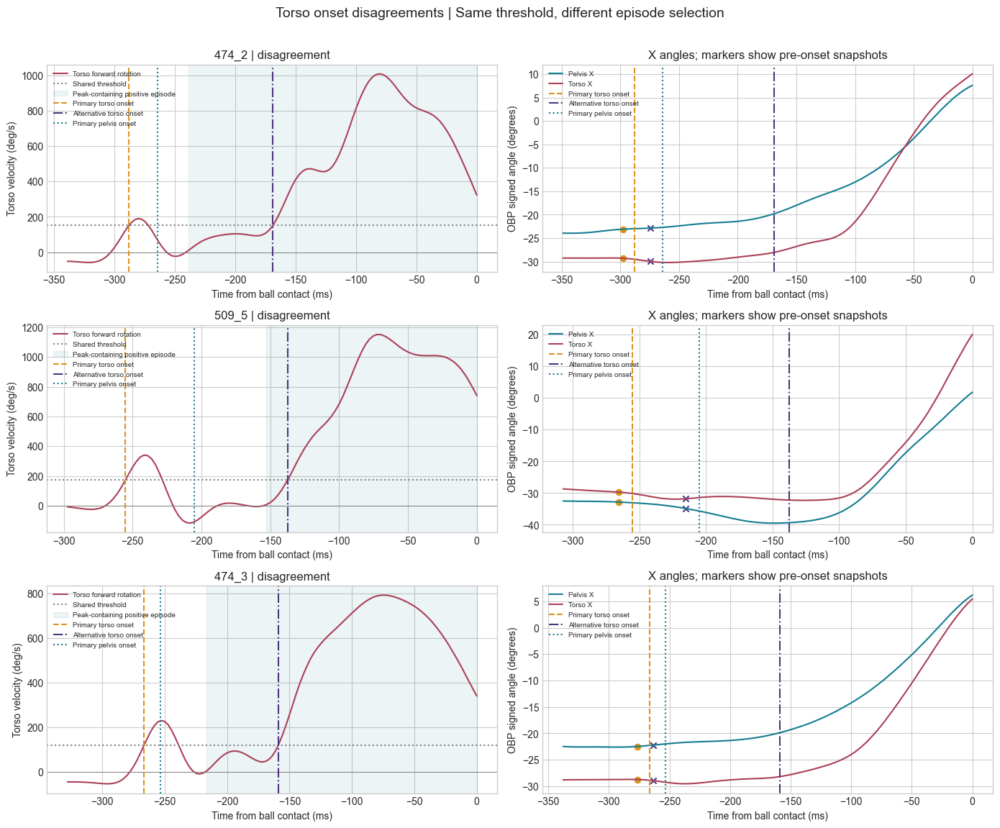

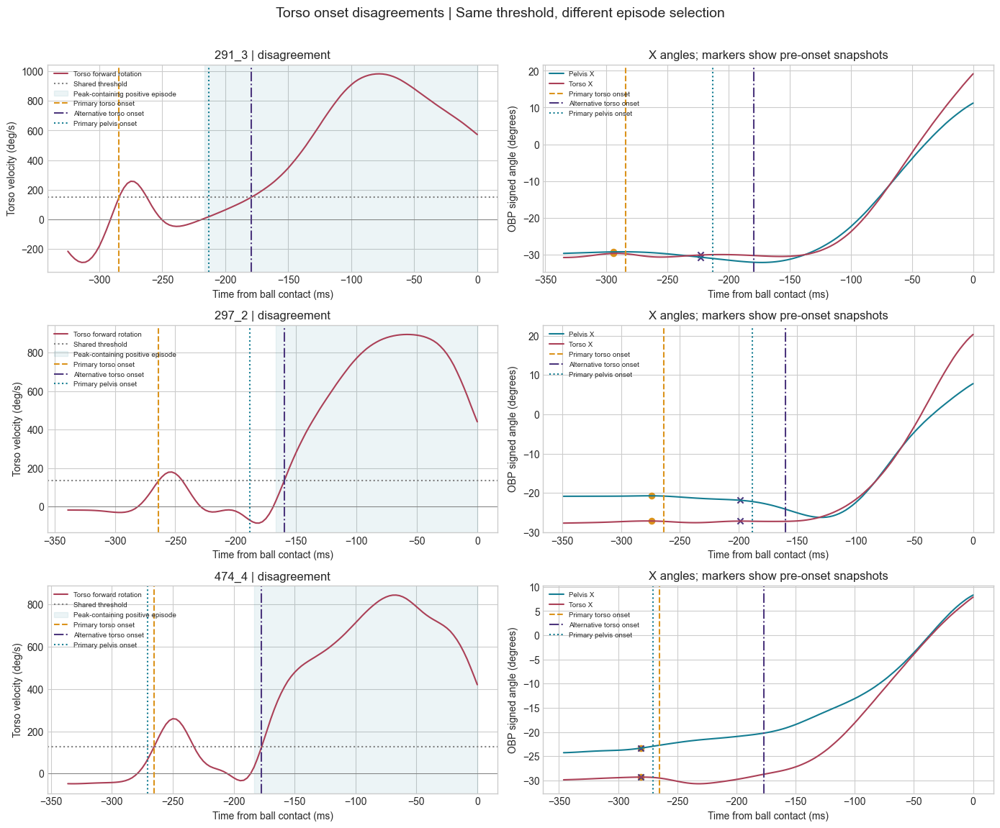

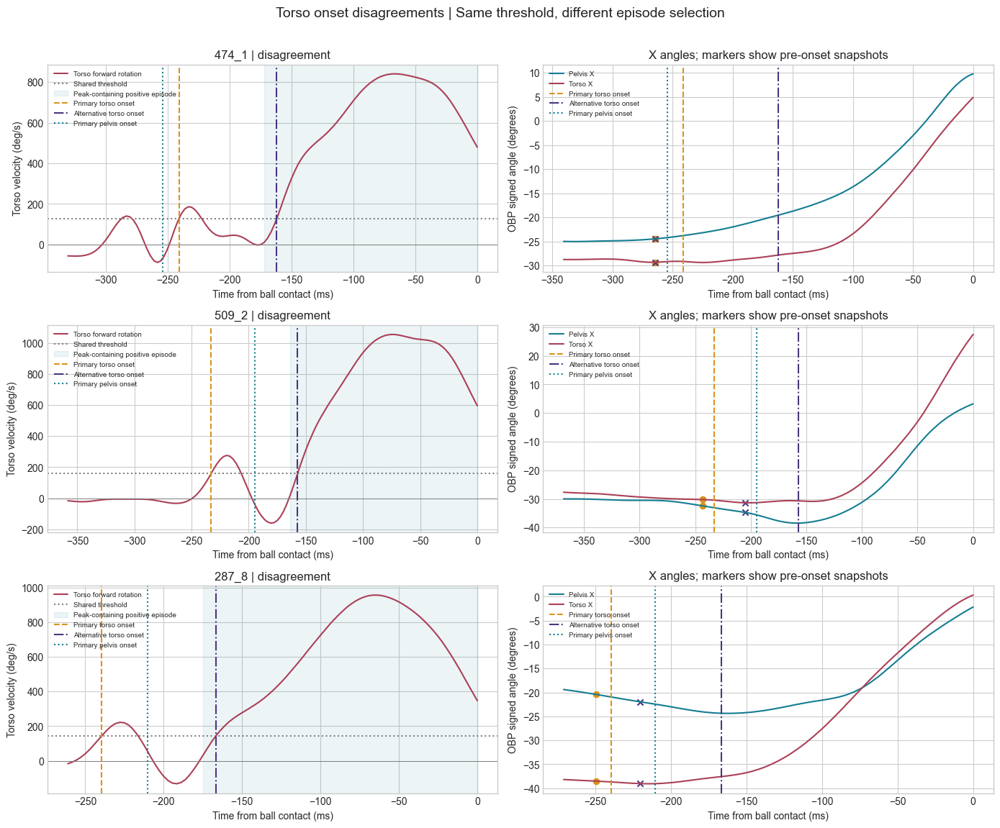

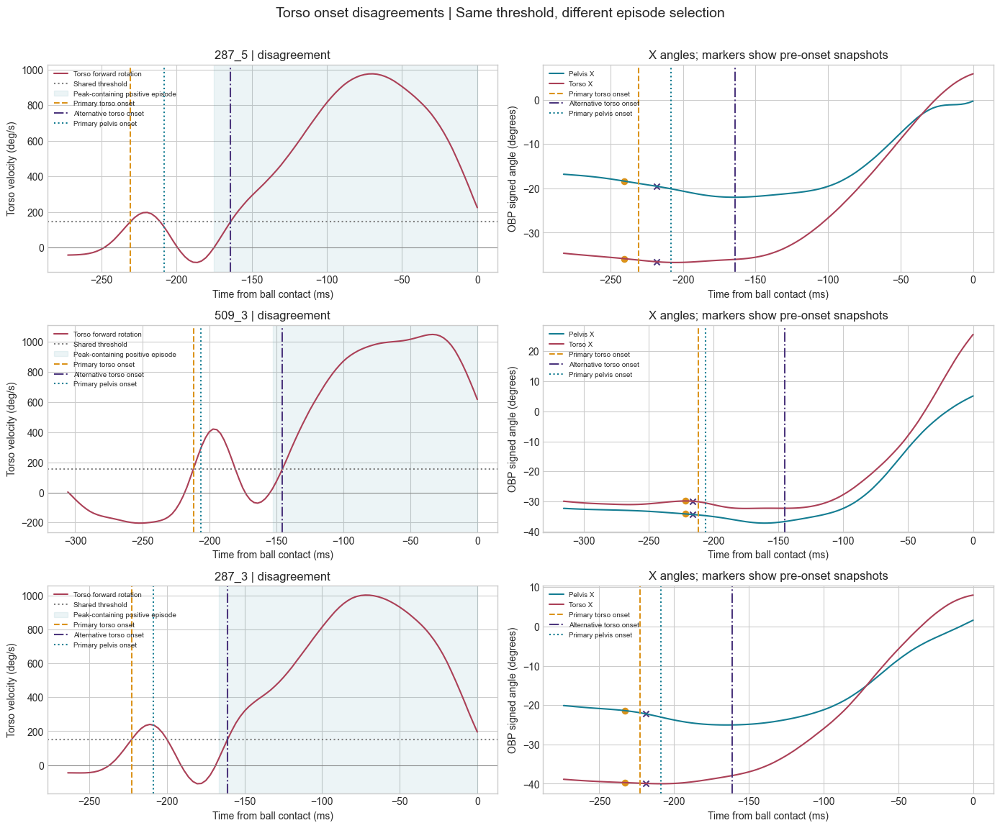

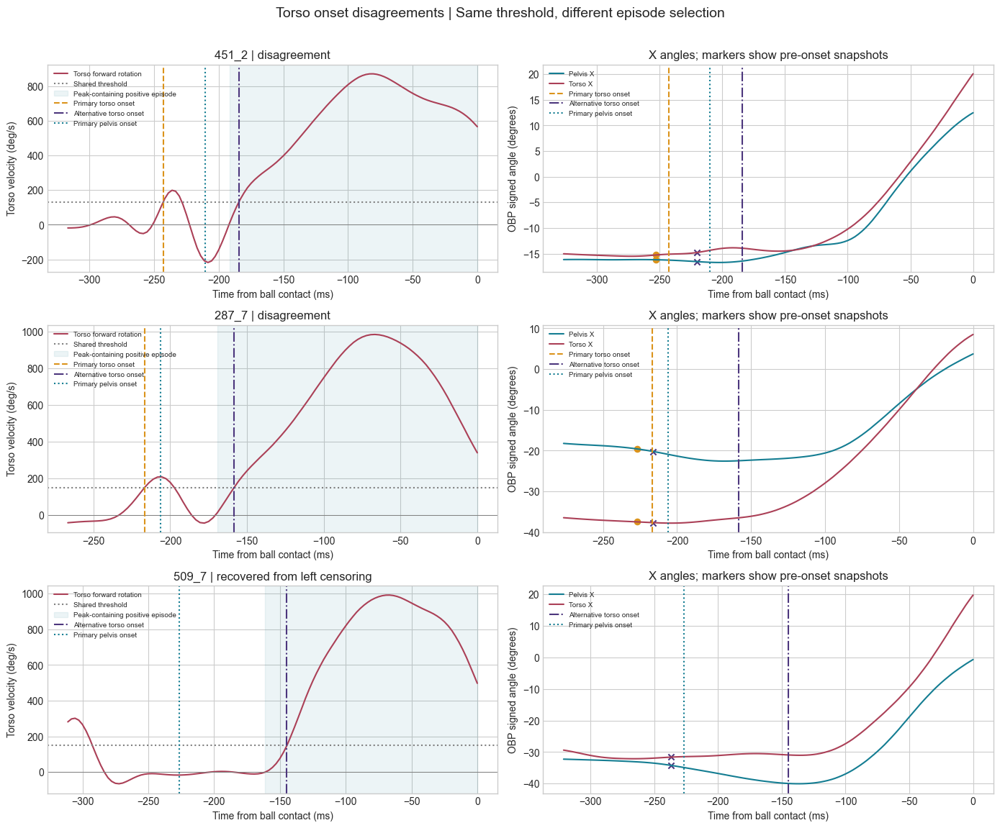

Torso audit complete; saved case tables, paired snapshot effects, matched profile changes, coverage, and every case timeline.
Report: c:\Users\brend\Documents\GitHub\baseball-biomechanics-analysis\results\rotation_onset_orientation\profile_stability_audit\torso_onset_disagreements\torso_onset_audit.html


Swing,Case,Onset shift (ms),Primary torso−pelvis lag (ms),Alternative lag (ms),Primary order,Alternative order,Pre-snapshot shift (ms)
474_2,disagreement,119.126,-23.827,95.298,torso first,pelvis first,23.827
509_5,disagreement,117.807,-50.168,67.639,torso first,pelvis first,50.168
474_3,disagreement,107.439,-12.994,94.445,torso first,pelvis first,12.994
291_3,disagreement,104.713,-71.458,33.255,torso first,pelvis first,71.458
297_2,disagreement,103.938,-75.362,28.576,torso first,pelvis first,75.362
474_4,disagreement,88.265,5.462,93.727,pelvis first,pelvis first,0.000
474_1,disagreement,78.883,13.343,92.226,pelvis first,pelvis first,0.000
509_2,disagreement,75.654,-38.120,37.534,torso first,pelvis first,38.120
287_8,disagreement,72.816,-29.069,43.748,torso first,pelvis first,29.069
287_5,disagreement,66.536,-22.591,43.946,torso first,pelvis first,22.591

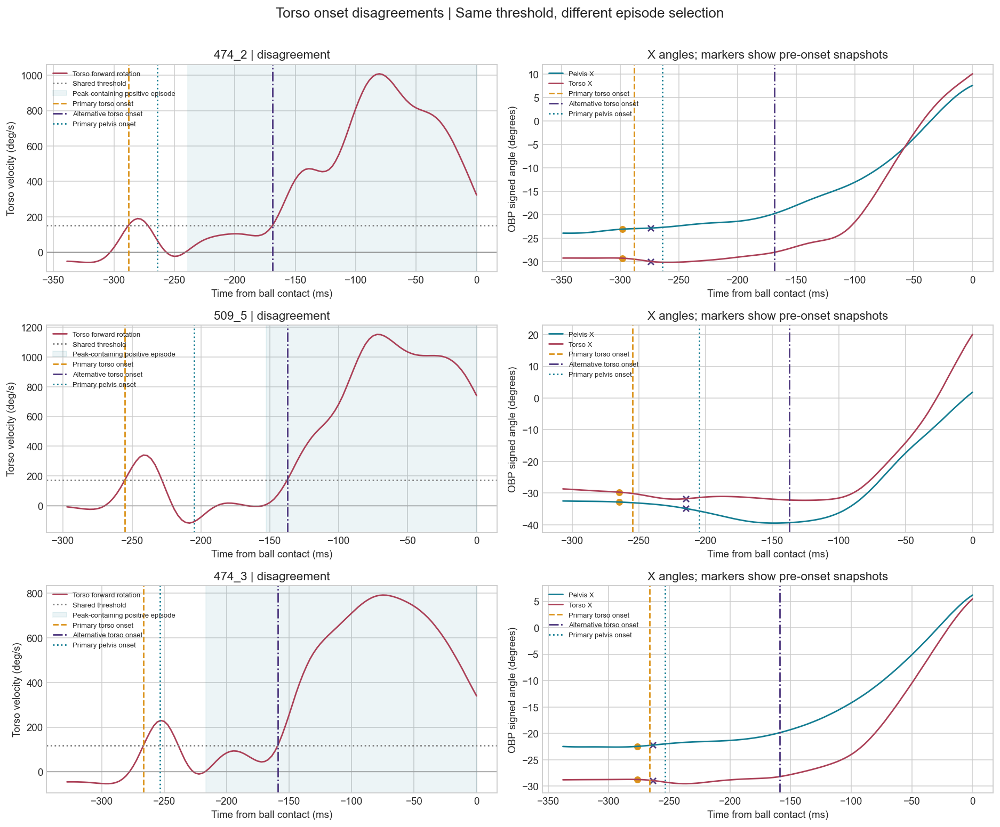
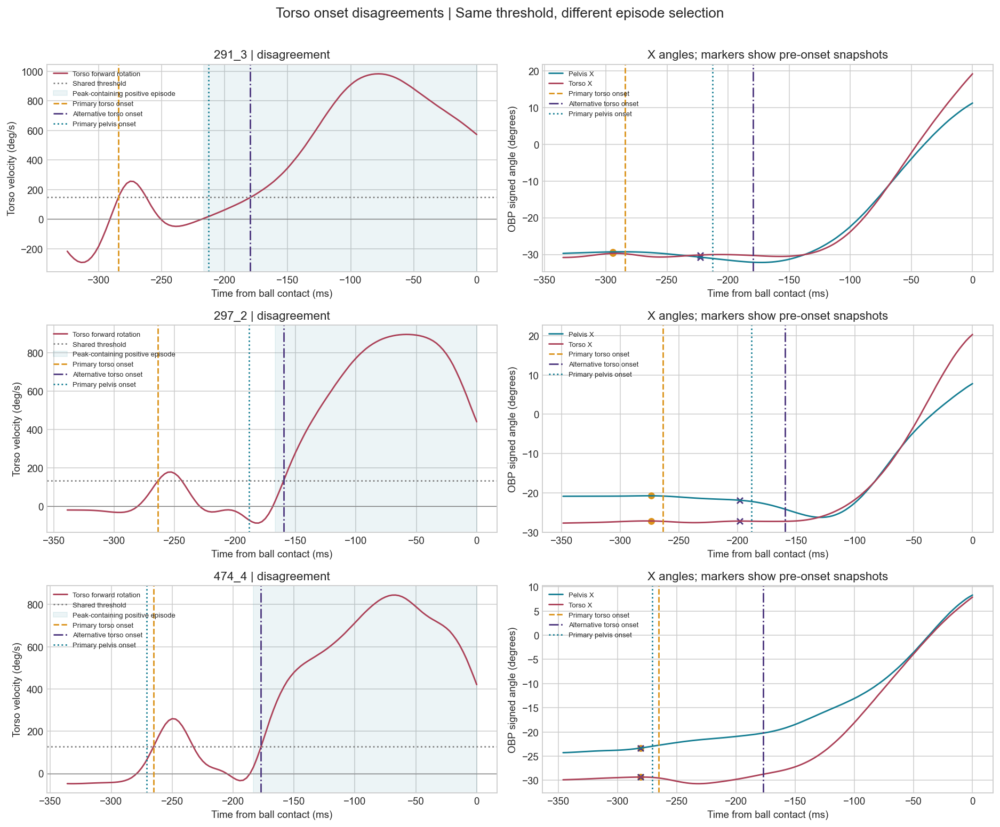
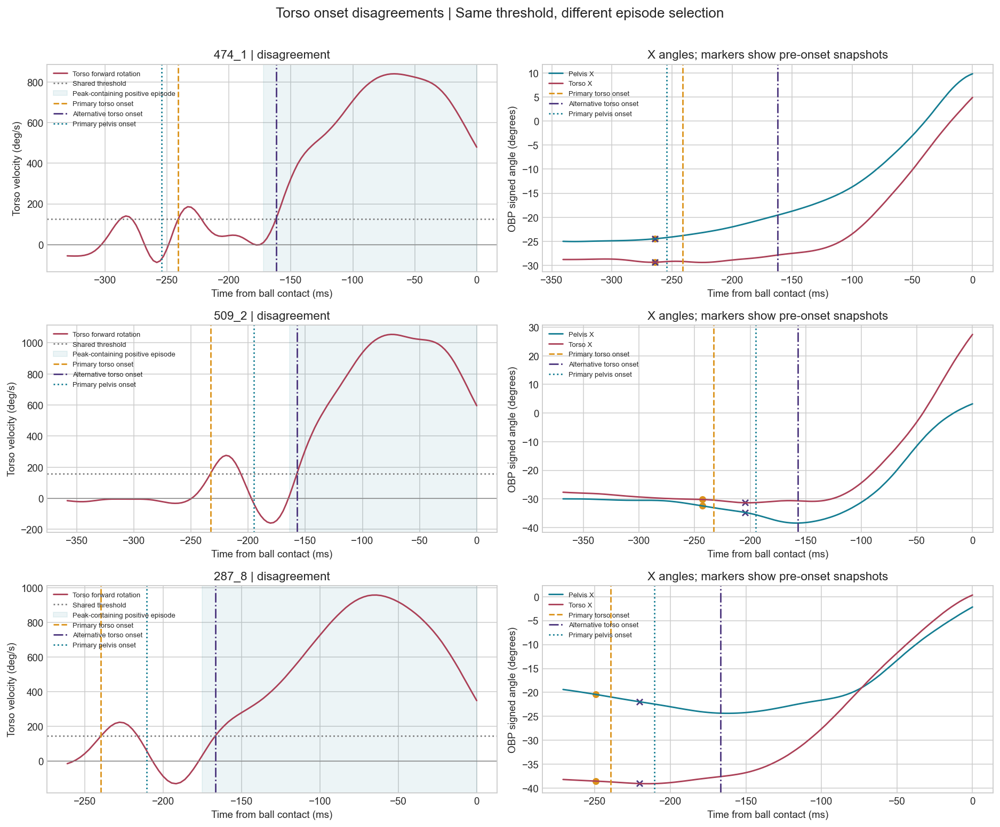
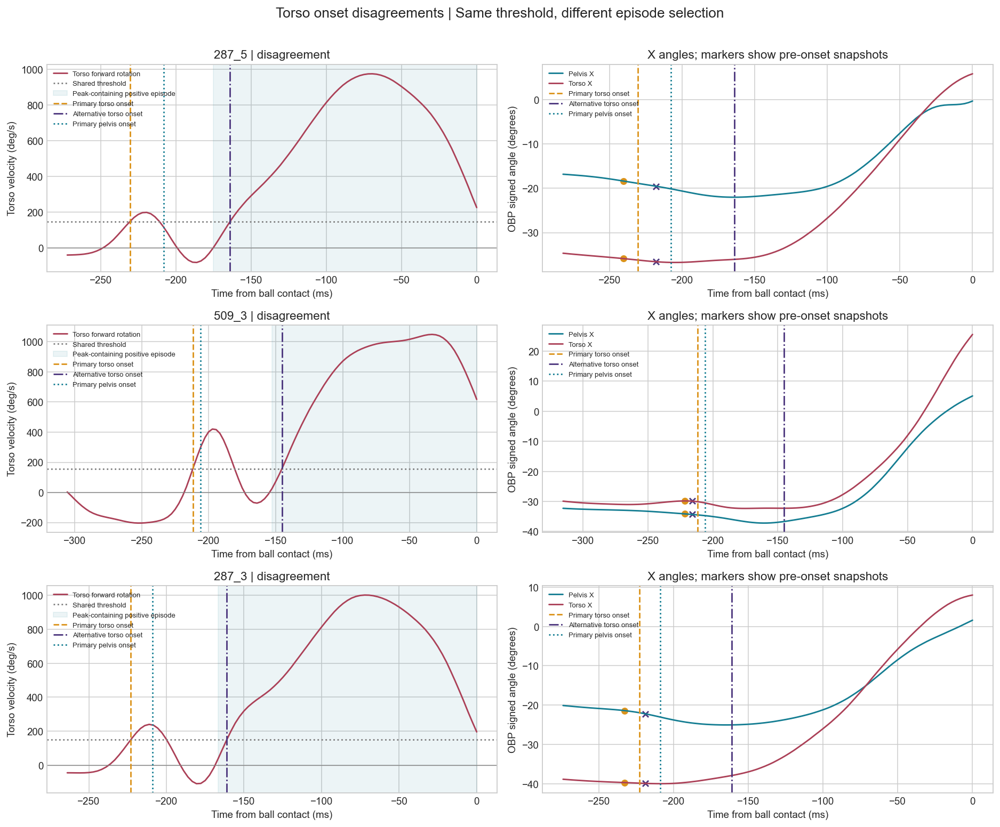
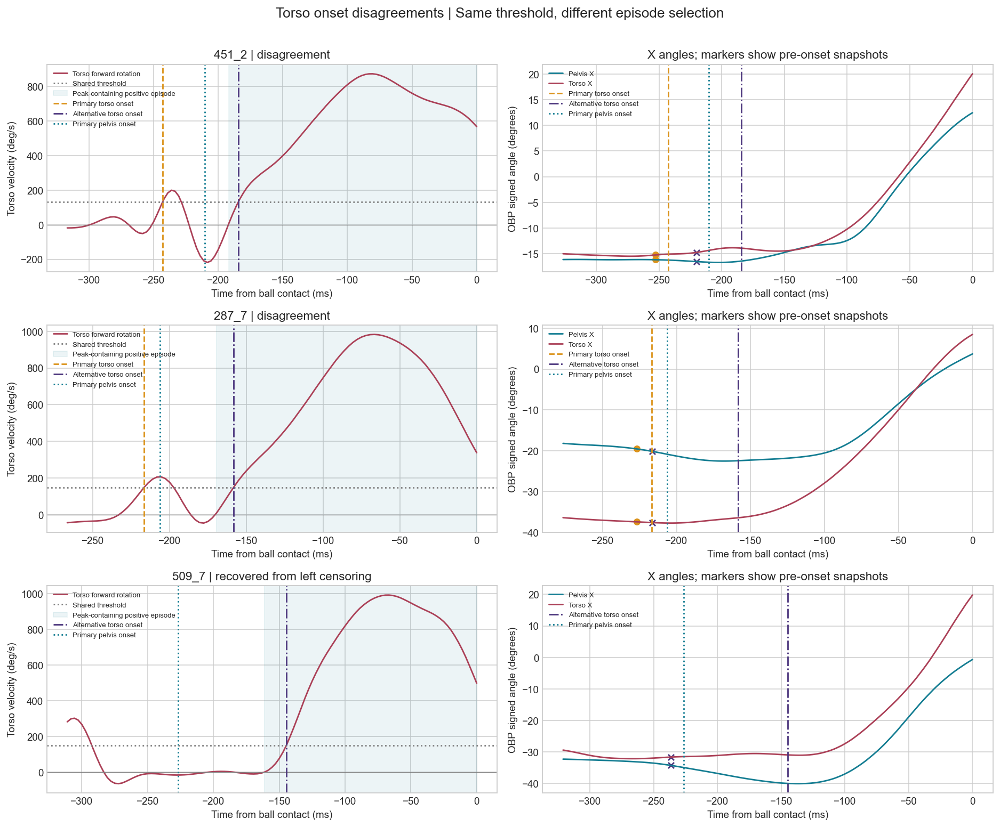

In [13]:
profile_changes=[]
for identity,g in torso_impact.groupby(GROUP,sort=False):
    matched=g.loc[g.primary_state.eq('detected') & g.alternative_state.eq('detected')]
    n=len(matched)
    if n<MIN_VALID_SWINGS:
        continue
    pid=' / '.join(map(str,identity))
    for label in ('torso_snapshot','pre_snapshot'):
        for c in ('pelvis_angle_x','torso_angle_x'):
            a=matched[label+'__'+c+'__primary'];b=matched[label+'__'+c+'__alternative']
            profile_changes.append({'profile_id':pid,'snapshot':label,'angle':c,'paired_swings':n,
                'disagreeing_swings':int(matched.status.eq('disagreement').sum()),
                'primary_mean_deg':a.mean(),'alternative_mean_deg':b.mean(),'mean_change_deg':b.mean()-a.mean(),
                'primary_sd_deg':a.std(ddof=1),'alternative_sd_deg':b.std(ddof=1),'sd_change_deg':b.std(ddof=1)-a.std(ddof=1)})
torso_profile_changes=pd.DataFrame(profile_changes)
torso_profile_changes.to_csv(TORSO_OUT/'matched_profile_changes.csv',index=False)
coverage=torso_impact.groupby(GROUP).agg(total_pelvis_valid=('session_swing','size'),
    primary_torso_detected=('primary_state',lambda v:int(v.eq('detected').sum())),
    alternative_torso_detected=('alternative_state',lambda v:int(v.eq('detected').sum())),
    newly_detected=('status',lambda v:int(v.eq('recovered_from_left_censoring').sum()))).reset_index()
coverage['primary_meets_minimum']=coverage.primary_torso_detected>=MIN_VALID_SWINGS
coverage['alternative_meets_minimum']=coverage.alternative_torso_detected>=MIN_VALID_SWINGS
coverage.to_csv(TORSO_OUT/'torso_detection_profile_coverage.csv',index=False)
print('Matched profile comparisons retain identical swings for both definitions; recovered cases are excluded from numerical deltas.')
print('Sequence labels changed in',int(paired_cases.order_changed.sum()),'of',len(paired_cases),'paired disagreements.')
print('Pre-onset times changed by more than one sample in',int(paired_cases.pre_time_changed_more_than_one_sample.sum()),'of those swings.')

torso_images=[]
case_records=list(cases.to_dict(orient='records'))
for start in range(0,len(case_records),3):
    batch=case_records[start:start+3]
    fig,axes=plt.subplots(len(batch),2,figsize=(14,3.9*len(batch)),squeeze=False)
    for axes_row,case in zip(axes,batch):
        row,tr=torso_traces[case['session_swing']]
        ax,bx=axes_row
        time_ms=1000*(tr['time']-row['contact_time'])
        angle_ms=1000*(tr['angle_time']-row['contact_time'])
        ax.plot(time_ms,tr['rates'][:,1],color='#ab4057',label='Torso forward rotation')
        ax.axhline(0,color='gray',lw=.7)
        ax.axhline(row['torso_threshold_dps'],color='gray',ls=':',label='Shared threshold')
        if np.isfinite(case['peak_episode_start_s']):
            ax.axvspan(1000*(case['peak_episode_start_s']-row['contact_time']),1000*(case['peak_episode_end_s']-row['contact_time']),color='#147d92',alpha=.08,label='Peak-containing positive episode')
        for s,color in [('pelvis','#147d92'),('torso','#ab4057')]:
            bx.plot(angle_ms,tr['angles'][:,CHANNELS.index(s+'_angle_x')],color=color,label=s.title()+' X')
        for when,color,style,label in [(case['primary_torso_s'],'#db931b','--','Primary torso onset'),
            (case['alternative_torso_s'],'#4c367d','-.','Alternative torso onset'),
            (row['pelvis_onset_s'],'#147d92',':','Primary pelvis onset')]:
            if np.isfinite(when):
                for panel in (ax,bx):
                    panel.axvline(1000*(when-row['contact_time']),color=color,ls=style,label=label)
        for when,color,marker in [(case['primary_pre_s'],'#db931b','o'),(case['alternative_pre_s'],'#4c367d','x')]:
            if np.isfinite(when):
                values=snapshot_at(tr,when)
                bx.scatter([1000*(when-row['contact_time'])]*2,[values[CHANNELS.index('pelvis_angle_x')],values[CHANNELS.index('torso_angle_x')]],color=color,marker=marker,s=35)
        ax.set(title=case['session_swing']+' | '+case['status'].replace('_',' '),ylabel='Torso velocity (deg/s)',xlabel='Time from ball contact (ms)')
        bx.set(title='X angles; markers show pre-onset snapshots',ylabel='OBP signed angle (degrees)',xlabel='Time from ball contact (ms)')
        ax.legend(fontsize=7,loc='upper left');bx.legend(fontsize=7,loc='upper left')
    fig.suptitle('Torso onset disagreements | Same threshold, different episode selection',fontsize=14)
    fig.tight_layout(rect=(0,0,1,.97))
    path=TORSO_FIG/f'case_review_{start//3+1:02d}.png'
    fig.savefig(path,dpi=135,bbox_inches='tight');torso_images.append(path);plt.show()

readable=cases[case_columns].rename(columns={'session_swing':'Swing','status':'Case','onset_shift_ms':'Onset shift (ms)',
    'primary_lag_ms':'Primary torso−pelvis lag (ms)','alternative_lag_ms':'Alternative lag (ms)',
    'primary_order':'Primary order','alternative_order':'Alternative order','pre_time_shift_ms':'Pre-snapshot shift (ms)'})
torso_section='<section style="overflow-x:auto"><h2>Torso-onset disagreement audit</h2><p>All primary pelvis-onset measurements are preserved. The alternative identifies a sustained crossing within the positive-velocity episode containing the torso precontact peak, using the original threshold. Neither detector is treated as ground truth.</p>'
torso_section+=f'<p>{len(paired_cases)} paired disagreements; {len(recovered_cases)} previously censored case with an alternative detection. {int(paired_cases.order_changed.sum())} paired sequence labels changed. Numerical snapshot deltas use paired disagreements only.</p>'
torso_section+=readable.round(3).to_html(index=False)
torso_section+='<h3>Snapshot effects in paired disagreements</h3>'+snapshot_impact.round(3).to_html(index=False)
for path in torso_images:
    torso_section+=embed_image(path)
torso_section+='<h3>Matched profile sensitivity</h3><p>Each profile comparison uses identical swings under both definitions and requires the original minimum count. Newly detected cases are reported separately in the coverage export. A different onset can change sequence labels and pose timing without proving a primary detection invalid.</p>'
affected_profiles=torso_profile_changes.loc[torso_profile_changes.disagreeing_swings.gt(0)]
torso_section+=affected_profiles.round(3).to_html(index=False)
torso_section+='<p>Episode selection is sensitive to brief zero crossings and sign reversals. Figures are retrospective motion-capture diagnostics. These comparisons do not validate biological onset, establish causal performance effects, or justify deleting swings.</p></section>'
torso_report='<!doctype html><html><head><meta charset="utf-8"><title>Torso-onset disagreement audit</title><style>body{font:15px system-ui;max-width:1400px;margin:25px auto;padding:20px;color:#203446}table{display:block;overflow:auto;border-collapse:collapse;font-size:12px}td,th{padding:7px;border-bottom:1px solid #dce3e9}p{line-height:1.5}</style></head><body>'+torso_section+'</body></html>'
(TORSO_OUT/'torso_onset_audit.html').write_text(torso_report,encoding='utf-8')
report=report.replace('<h2>Interpretation</h2>',torso_section+'<h2>Interpretation</h2>')
(OUT/'rotation_onset_orientation.html').write_text(report,encoding='utf-8')
manifest['torso_onset_audit']={'paired_disagreements':len(paired_cases),'recovered_cases':len(recovered_cases),
    'sequence_changes':int(paired_cases.order_changed.sum()),'matched_profiles':int(torso_profile_changes.profile_id.nunique()) if not torso_profile_changes.empty else 0,
    'primary_common_snapshots_preserved':True,'automatic_replacement':False,'outputs_directory':str(TORSO_OUT)}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Torso audit complete; saved case tables, paired snapshot effects, matched profile changes, coverage, and every case timeline.')
print('Report:',TORSO_OUT/'torso_onset_audit.html')
display(HTML(torso_report))

Finished assessment report: c:\Users\brend\Documents\GitHub\baseball-biomechanics-analysis\results\rotation_onset_orientation\study_summary.html
Primary snapshots: 642 | selectable reconstructed poses: 642
Primary metrics preserved; influence notice and onset-sensitive secondary views are explicit.



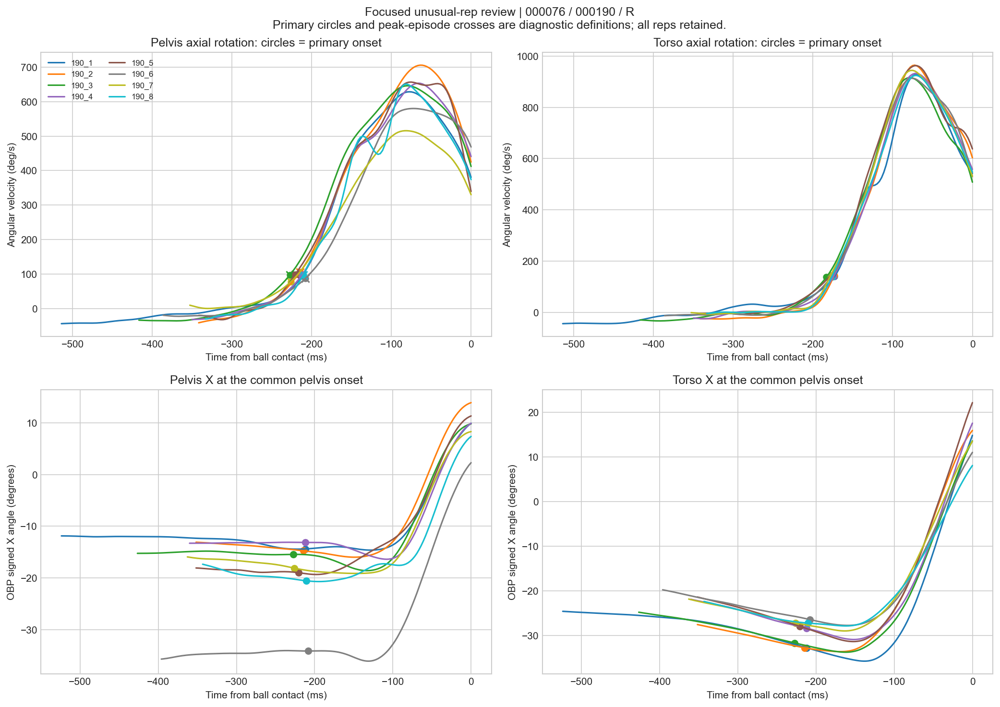
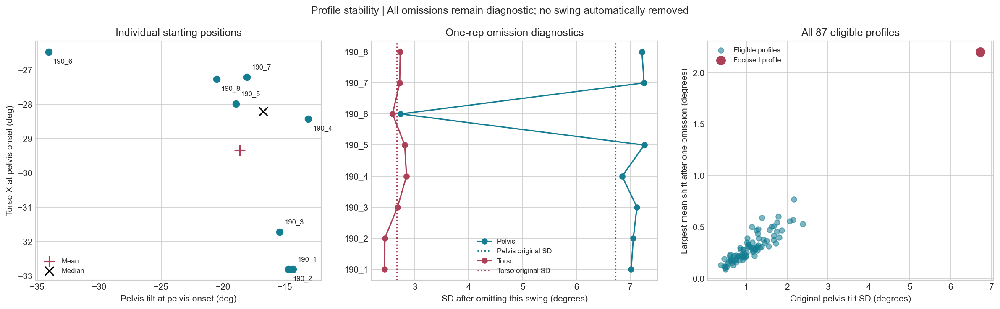
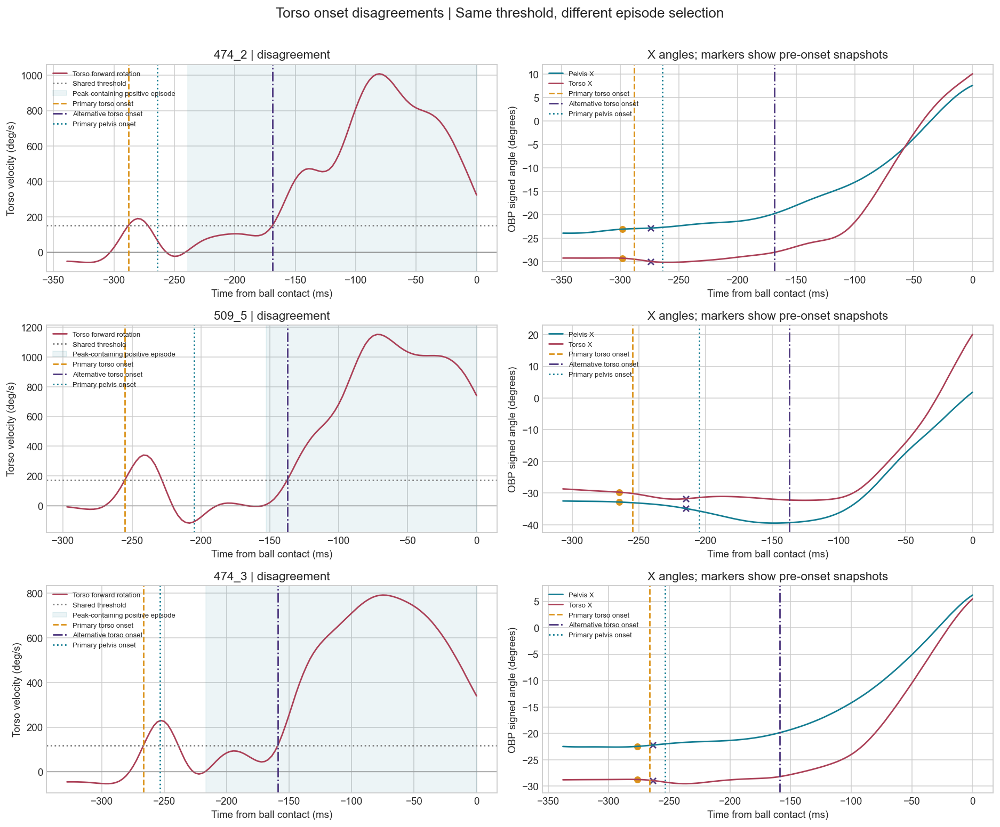
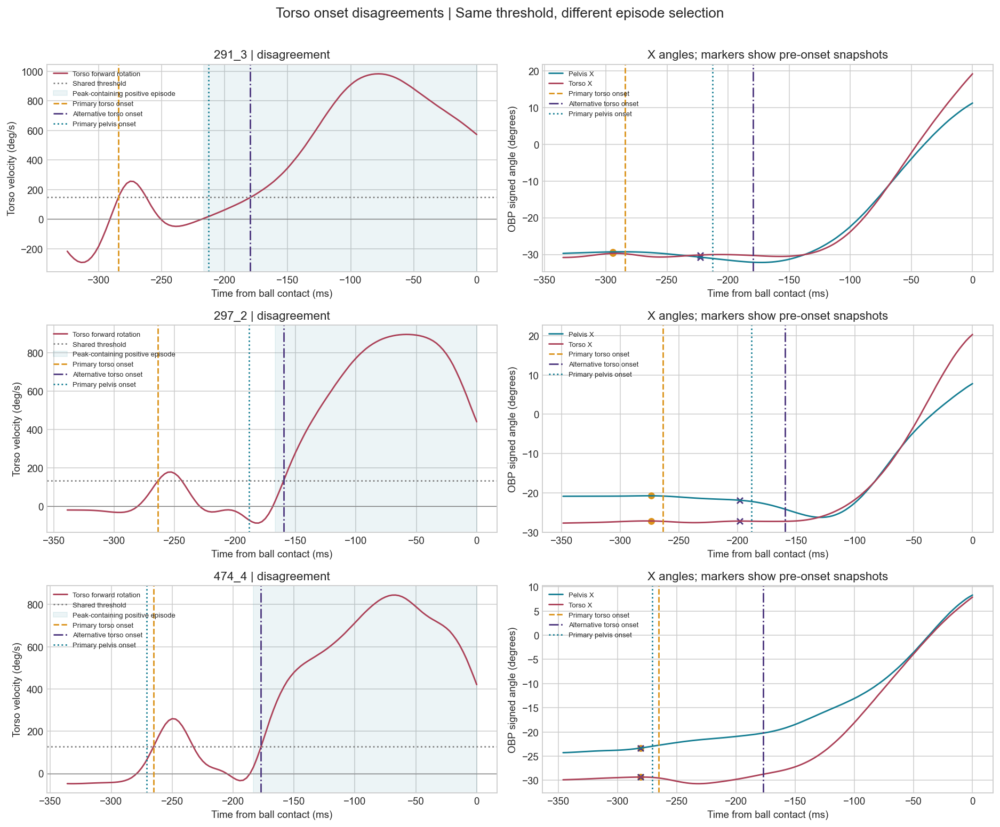
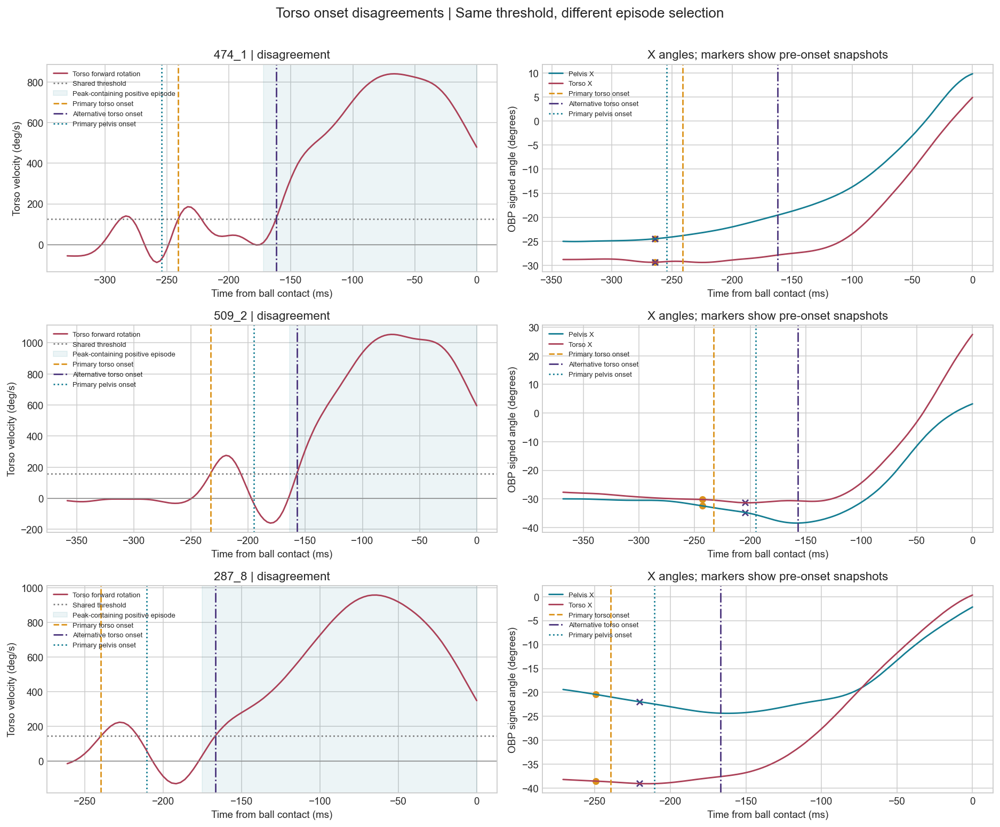
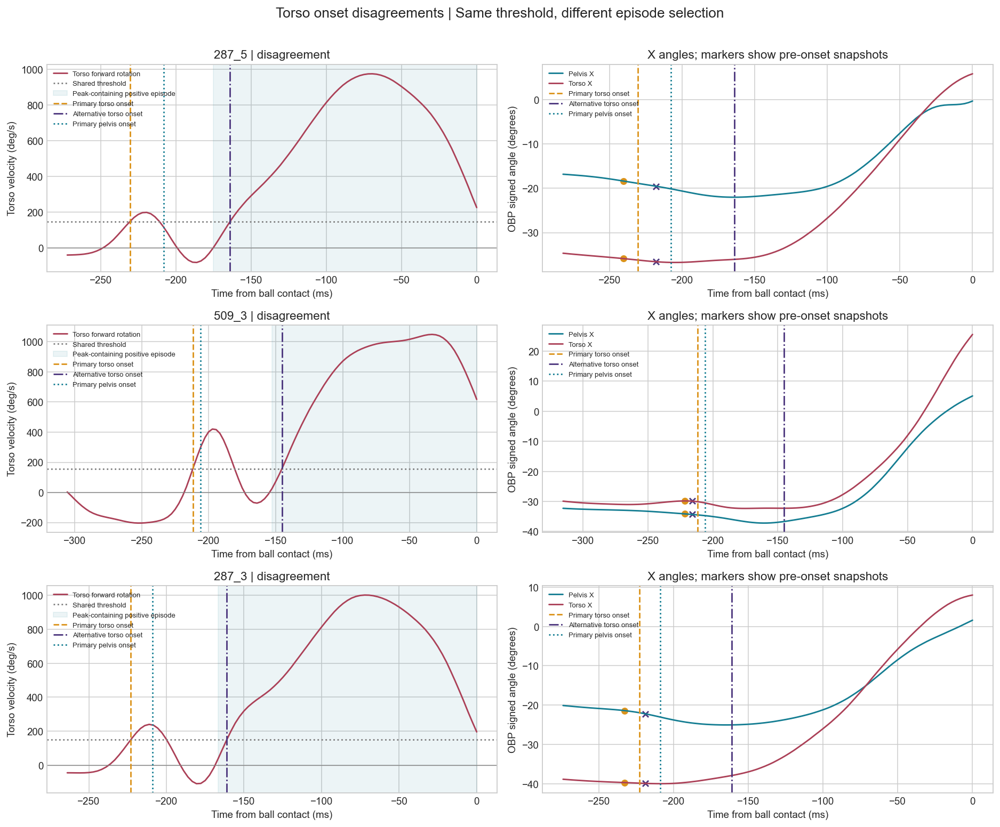
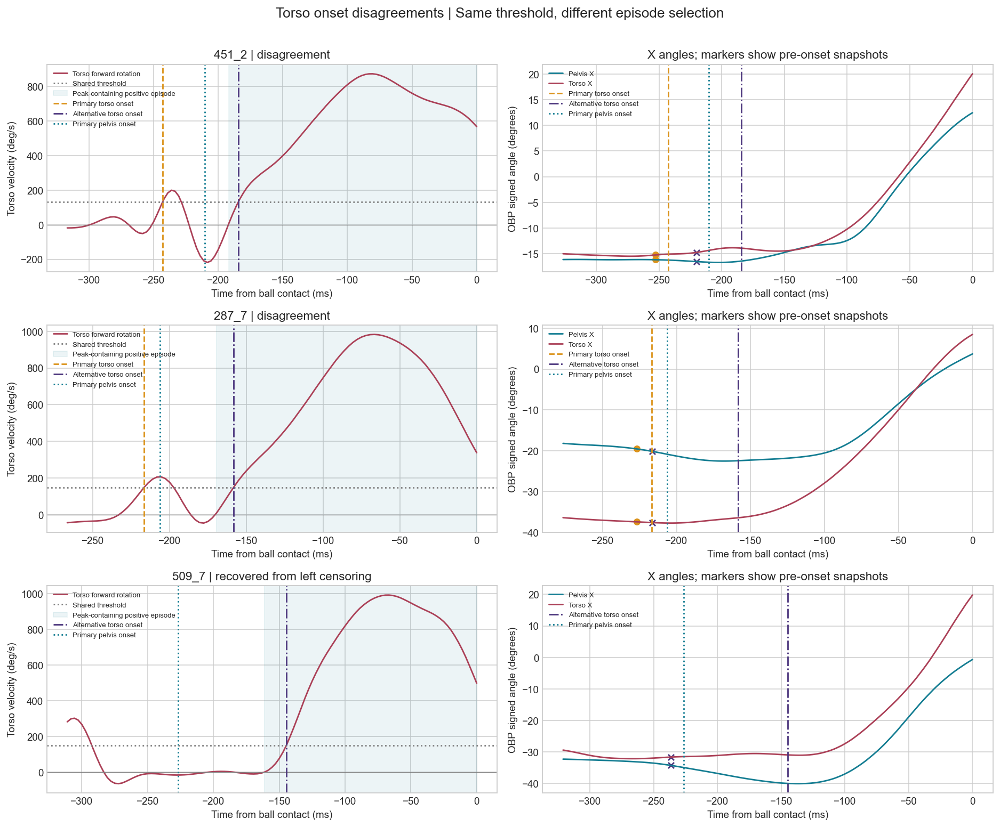
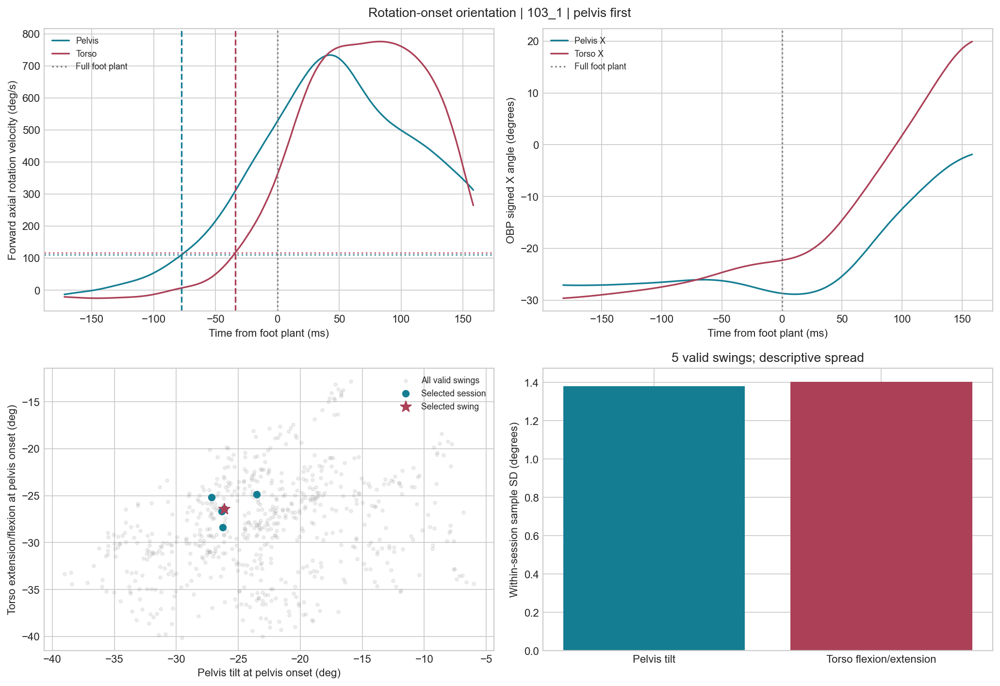
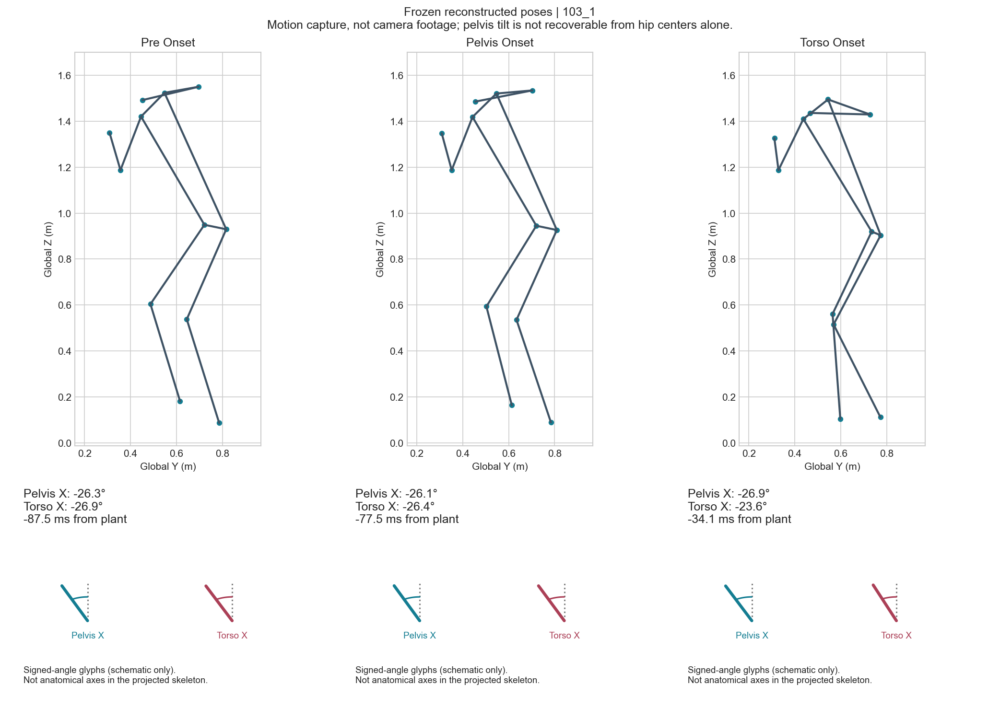

In [14]:
pose_nodes = ['left_hip','right_hip','lsjc','rsjc','lejc','rejc','lwjc','rwjc','lkjc','rkjc','lajc','rajc']
pose_edges = [[pose_nodes.index(a),pose_nodes.index(b)] for a,b in [('left_hip','right_hip'),('lsjc','rsjc'),('left_hip','lsjc'),('right_hip','rsjc'),('lsjc','lejc'),('lejc','lwjc'),('rsjc','rejc'),('rejc','rwjc'),('left_hip','lkjc'),('lkjc','lajc'),('right_hip','rkjc'),('rkjc','rajc')]]
pose_lookup,pose_audit = {},[]
if MAKE_POSE:
    try:
        landmark_path=ensure_signal('landmarks')
        pose_cols=[a+'_'+b for a in pose_nodes for b in 'xyz']
        chunks=pd.read_csv(landmark_path,usecols=['session_swing','time']+EVENTS+pose_cols,dtype={'session_swing':str},chunksize=100000)
        pending={}
        targets=set(common.session_swing)
        for chunk in chunks:
            for key,g in chunk.loc[chunk.session_swing.isin(targets)].groupby('session_swing',sort=False):
                pending.setdefault(str(key),[]).append(g)
        primary_by_key=common.set_index('session_swing')
        for key in common.session_swing:
            try:
                lm=pd.concat(pending.pop(key,[]),ignore_index=True).sort_values('time')
                check_keys(lm,'landmark snapshot',['session_swing','time'])
                e=event_values(lm);primary=primary_by_key.loc[key]
                if any(abs(e[c]-primary[c])>1e-4 for c in EVENTS):
                    raise ValueError('landmark/angle event disagreement')
                when=float(primary.pelvis_onset_s)
                t,x=window(lm,pose_cols,when-.010,when+.010)
                p=np.array([np.interp(when,t,x[:,j]) for j in range(len(pose_cols))]).reshape(len(pose_nodes),3)
                pose_lookup[key]=p.tolist()
                pose_audit.append({'session_swing':key,'status':'available'})
            except ValueError as exc:
                pose_audit.append({'session_swing':key,'status':str(exc)})
    except (OSError,ValueError,KeyError) as exc:
        print('Optional selectable poses unavailable:',exc)
pd.DataFrame(pose_audit,columns=['session_swing','status']).to_csv(OUT/'report_pose_coverage.csv',index=False)

assessment_records=[]
for _,r in common.iterrows():
    assessment_records.append({'id':r.session_swing,'profile':' / '.join(str(r[c]) for c in GROUP),
        'angles':[float(r['pelvis_onset__'+c]) for c in CHANNELS],
        'time_ms':1000*(r.pelvis_onset_s-r.fp_100_time),
        'pose':pose_lookup.get(r.session_swing)})
stability_lookup={}
for _,r in stability.iterrows():
    stability_lookup[r.profile_id]={'pelvis_mean_shift':float(r[pc+'__max_absolute_mean_shift']),
        'torso_mean_shift':float(r[tc+'__max_absolute_mean_shift']),
        'swing':str(r[pc+'__most_mean_influential_swing'])}
focus_stats=stability.loc[stability.profile_id.eq(focus_id)].iloc[0]
focus_omit=focus_loo.loc[focus_loo.omitted_swing.eq(str(focus_stats[pc+'__most_mean_influential_swing']))].iloc[0]
notice_data={'profile':focus_id,'swing':str(focus_omit.omitted_swing),'original_sd':float(focus_stats[pc+'__sd']),
             'remaining_sd':float(focus_omit[pc+'__remaining_sd']),'mean_shift':float(focus_omit[pc+'__mean_shift'])}
affected_torso_profiles=cases[GROUP].drop_duplicates().astype(str).agg(' / '.join,axis=1).tolist()
assessment_data={'records':assessment_records,'minimum':MIN_VALID_SWINGS,'stability':stability_lookup,
    'influence':notice_data,'torso_profiles':affected_torso_profiles,'edges':pose_edges,
    'counts':{'valid':len(common),'eligible':int(profile.eligible.sum()),'evaluated':len(ag)}}
labels=['Pelvis tilt','Pelvis lateral tilt','Pelvis axial orientation','Torso flexion / extension','Torso lateral tilt','Torso axial orientation']

summary_html=r"""<!doctype html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Rotation-onset orientation assessment</title>
<style>*{box-sizing:border-box}body{margin:0;background:#f3f5f7;color:#20313c;font:15px system-ui,Arial,sans-serif}main{max-width:1180px;margin:auto;padding:28px 22px 60px}h1{font-size:32px;line-height:1.15;max-width:780px;margin:8px 0 14px}h2{font-size:21px;margin:0 0 16px}p{line-height:1.55}.eyebrow{letter-spacing:.12em;text-transform:uppercase;font-size:12px;font-weight:700;color:#147d92}.lead{max-width:850px;color:#4d606b}.strip,.panel{background:white;border:1px solid #dbe2e7;border-radius:10px;padding:20px;margin:18px 0}.strip{display:flex;gap:35px;flex-wrap:wrap}.strip strong{font-size:24px;display:block}.strip span,.muted{color:#62737d;font-size:13px}.controls{display:flex;gap:20px;flex-wrap:wrap;margin-bottom:15px}label{font-size:13px;font-weight:600;display:block}select{display:block;padding:10px;margin-top:7px;max-width:100%;min-width:180px;border:1px solid #bdcad2;border-radius:5px;background:white;color:#20313c;font:inherit}.grid{display:grid;grid-template-columns:1fr 1fr;gap:20px}.cards{display:grid;grid-template-columns:1fr 1fr;gap:12px;margin:15px 0}.card{padding:16px;background:#f4f7f8;border-left:3px solid #147d92}.card:nth-child(2){border-left-color:#ab4057}.card b{display:block;font-size:25px;margin:6px 0}.notice{padding:15px;border-left:4px solid #bc7c20;background:#fff6e6;margin:15px 0;line-height:1.5}.notice:empty{display:none}.info{background:#edf5f7;border-left-color:#147d92}svg{width:100%;height:auto;display:block;background:white}table{border-collapse:collapse;width:100%;font-size:13px}td,th{padding:9px;text-align:left;border-bottom:1px solid #e0e5e9}th{font-weight:600}.scroll{overflow:auto}details{background:white;border:1px solid #dbe2e7;border-radius:8px;margin:12px 0;padding:17px}summary{cursor:pointer;font-weight:650}details>div{margin-top:20px;overflow:auto}details img{max-width:100%}a{color:#147d92}.footer{font-size:13px;color:#62737d;margin-top:25px}@media(max-width:760px){.grid{grid-template-columns:1fr}main{padding:20px 12px}h1{font-size:26px}.strip{gap:22px}.cards{grid-template-columns:1fr 1fr}select{min-width:140px}}</style></head><body><main>
<div class="eyebrow">Study 19 · OpenBiomechanics</div><h1>Pelvis and torso orientation at rotation onset</h1>
<p class="lead">A descriptive starting-position assessment. Both segments are measured at the <strong>same detected pelvis onset</strong>. Compare each hitter’s position across swings and inspect how consistently it is reproduced within the session.</p>
<div class="strip"><div><strong>VALID</strong><span>valid pelvis-onset snapshots</span></div><div><strong>ELIGIBLE</strong><span>profiles with at least MINIMUM swings</span></div><div><strong>EVALUATED</strong><span>swings evaluated</span></div></div>
<section class="panel"><div class="controls"><label>Hitter / session / batting side<select id="profileSelect"></select></label><label>Individual swing<select id="swingSelect"></select></label></div>
<div id="eligibilityNotice" class="notice"></div><div id="influenceNotice" class="notice"></div><div id="torsoNotice" class="notice info"></div>
<div class="cards"><div class="card"><label>Session pelvis tilt</label><b id="pelvisMean"></b><span id="pelvisSpread"></span></div><div class="card"><label>Session torso flexion / extension</label><b id="torsoMean"></b><span id="torsoSpread"></span></div></div>
<p class="muted">Signed OBP angles: pelvis posterior (+) / anterior (−) tilt; torso extension (+) / flexion (−). SD is observed within-session spread, not test–retest reliability or confidence in the mean.</p>
<div class="grid"><div><h2>Start-position fingerprint</h2><svg id="fingerprint" viewBox="0 0 520 400" role="img" aria-label="Pelvis tilt against torso flexion at pelvis onset"></svg><p class="muted">Dots are swings; the red cross is the session mean. The selected swing has a dark outline. Axes use a common scale across sessions.</p></div>
<div><h2 id="poseHeading">Frozen pose at pelvis onset</h2><svg id="pose" viewBox="0 0 520 400" role="img" aria-label="Reconstructed joint centers in two global projections"></svg><p class="muted">Reconstructed motion capture, not camera footage. These global projections do not define the anatomical pelvis tilt angle; values below come from the processed angle channels.</p></div></div>
<p id="repContext"></p><div class="scroll"><table><thead><tr><th>Angle at the common pelvis onset</th><th>Selected swing</th><th>Session mean</th><th>Session SD</th></tr></thead><tbody id="angleRows"></tbody></table></div><p id="influenceContext" class="muted"></p></section>
<section class="panel"><h2>How to read this assessment</h2><p>The common pelvis-onset snapshot is the primary result. A consistent position is a description of this session, not a mechanical-quality grade or a prescribed target. The detector uses a sustained forward-rotation threshold and the subsequent pre-contact peak, so the assessment is retrospective.</p><p><strong>Torso-specific and pre-onset snapshots depend on the onset definition.</strong> The two torso definitions changed the sequence label in SEQUENCE of PAIRED paired disagreements. The separately detected alternative for RECOVERED censored case is shown without an invented baseline difference. Detailed comparisons are available below.</p></section>
<h2>Supporting diagnostics</h2><details><summary>Onset thresholds and coverage</summary><div>SENSITIVITY</div></details>
<details><summary>Unusual-rep influence and profile stability</summary><div>INFLUENCE_AUDIT</div></details>
<details><summary>Torso-onset disagreements and snapshot sensitivity</summary><div>TORSO_AUDIT</div></details>
<details><summary>Selected example: event timeline and secondary frozen snapshots</summary><div><p>These example figures remain tied to swing EXAMPLE. To regenerate them for another swing, set SELECTED_SWING in the first cell and rerun. The primary pose and angle table above follow the selectors.</p><p class="notice info">Pre-onset and torso-onset frames are secondary views sensitive to the detector definition. They do not establish that no movement had begun.</p>EXAMPLE_IMAGES</div></details>
<p class="footer">Source: <a href="https://github.com/drivelineresearch/openbiomechanics">Driveline OpenBiomechanics Dataset v1</a>. Review the upstream data license before sharing individual data or derived reports. No performance or causal model is fitted.</p>
<script>const assessment=PAYLOAD, angleLabels=LABELS;
const get=id=>document.getElementById(id), profiles=[...new Set(assessment.records.map(r=>r.profile))];
const option=(value,label)=>{const o=document.createElement('option');o.value=value;o.textContent=label;return o;};
for(const id of profiles){const n=assessment.records.filter(r=>r.profile===id).length;get('profileSelect').appendChild(option(id,id+' · '+n+' swings'));}
const mean=(rows,j)=>rows.reduce((a,r)=>a+r.angles[j],0)/rows.length;
const sd=(rows,j)=>rows.length>1?Math.sqrt(rows.reduce((a,r)=>a+(r.angles[j]-mean(rows,j))**2,0)/(rows.length-1)):null;
const fmt=x=>x===null?'Unavailable':x.toFixed(2)+'°';
function drawPose(rep){let content='';if(!rep.pose){get('pose').innerHTML='<text x="260" y="200" text-anchor="middle">Optional pose unavailable for this swing</text>';return;}
for(const [panel,horizontal,title] of [[0,1,'Global Y–Z'],[1,0,'Global X–Z']]){const origin=panel*260,points=rep.pose;
const low=Math.min(...points.map(p=>p[horizontal])),high=Math.max(...points.map(p=>p[horizontal]));const zmin=Math.min(...points.map(p=>p[2])),zmax=Math.max(...points.map(p=>p[2]));
const scale=Math.min(205/Math.max(high-low,.1),290/Math.max(zmax-zmin,.1));const cx=(low+high)/2,cz=(zmin+zmax)/2;
const x=p=>origin+130+(p[horizontal]-cx)*scale,y=p=>205-(p[2]-cz)*scale;
content+=`<text x="${origin+130}" y="28" text-anchor="middle" font-size="13">${title}</text>`;
for(const [a,b] of assessment.edges)content+=`<line x1="${x(points[a])}" y1="${y(points[a])}" x2="${x(points[b])}" y2="${y(points[b])}" stroke="#455d6b" stroke-width="3"/>`;
for(const p of points)content+=`<circle cx="${x(p)}" cy="${y(p)}" r="3.5" fill="#147d92"/>`;}
get('pose').innerHTML=content;}
function drawFingerprint(rows,rep){const all=assessment.records;let xmin=Math.min(...all.map(r=>r.angles[0]))-3,xmax=Math.max(...all.map(r=>r.angles[0]))+3,ymin=Math.min(...all.map(r=>r.angles[3]))-3,ymax=Math.max(...all.map(r=>r.angles[3]))+3;
const X=v=>65+(v-xmin)/(xmax-xmin)*420,Y=v=>330-(v-ymin)/(ymax-ymin)*285;
let s='<path d="M65 45V330H485" fill="none" stroke="#748892"/>';
for(let i=0;i<=4;i++){let x=xmin+(xmax-xmin)*i/4,y=ymin+(ymax-ymin)*i/4;s+=`<text x="${X(x)}" y="351" text-anchor="middle" font-size="12">${x.toFixed(0)}</text><text x="53" y="${Y(y)+4}" text-anchor="end" font-size="12">${y.toFixed(0)}</text>`;}
for(const r of rows)s+=`<circle cx="${X(r.angles[0])}" cy="${Y(r.angles[3])}" r="${r.id===rep.id?7:5}" fill="#147d92" stroke="${r.id===rep.id?'#20313c':'white'}" stroke-width="2"><title>${r.id}</title></circle>`;
const mx=X(mean(rows,0)),my=Y(mean(rows,3));s+=`<path d="M${mx-8} ${my}h16 M${mx} ${my-8}v16" stroke="#ab4057" stroke-width="3"/><text x="275" y="385" text-anchor="middle" font-size="13">Pelvis tilt (degrees)</text><text transform="translate(16 190) rotate(-90)" text-anchor="middle" font-size="13">Torso flexion / extension (degrees)</text>`;get('fingerprint').innerHTML=s;}
function draw(){const id=get('profileSelect').value,rows=assessment.records.filter(r=>r.profile===id),rep=rows.find(r=>r.id===get('swingSelect').value)||rows[0];
get('eligibilityNotice').textContent=rows.length<assessment.minimum?`${rows.length} swings: below the ${assessment.minimum}-swing minimum for primary profile reporting. Values remain visible for inspection.`:'';
const f=assessment.influence;get('influenceNotice').textContent=id===f.profile?`Influential rep: ${f.swing}. Omitting it changes pelvis SD from ${f.original_sd.toFixed(2)}° to ${f.remaining_sd.toFixed(2)}° and shifts the mean by ${f.mean_shift.toFixed(2)}°. All swings remain included. This does not establish that the rep is invalid.`:'';
get('torsoNotice').textContent=assessment.torso_profiles.includes(id)?'This session contains a torso-onset disagreement or censored case. The main pelvis-onset assessment is unaffected; inspect the torso audit before interpreting sequence or secondary snapshots.':'';
get('pelvisMean').textContent=fmt(mean(rows,0));get('torsoMean').textContent=fmt(mean(rows,3));get('pelvisSpread').textContent='Within-session SD '+fmt(sd(rows,0));get('torsoSpread').textContent='Within-session SD '+fmt(sd(rows,3));
get('repContext').textContent=`Swing ${rep.id} · Detected pelvis onset ${rep.time_ms.toFixed(1)} ms from full foot plant · ${rows.length} valid session swings`;
get('poseHeading').textContent='Frozen pose · swing '+rep.id;
get('angleRows').innerHTML=angleLabels.map((label,j)=>`<tr><td>${label}</td><td>${fmt(rep.angles[j])}</td><td>${fmt(mean(rows,j))}</td><td>${fmt(sd(rows,j))}</td></tr>`).join('');
const st=assessment.stability[id];get('influenceContext').textContent=st?`Largest mean shift after omitting any one swing: pelvis ${st.pelvis_mean_shift.toFixed(2)}°, torso ${st.torso_mean_shift.toFixed(2)}°. Omission results are diagnostics; smaller remaining samples can fall below the reporting minimum.`:'Omission summaries require the primary minimum swing count.';
drawFingerprint(rows,rep);drawPose(rep);}
function changeProfile(){const rows=assessment.records.filter(r=>r.profile===get('profileSelect').value);get('swingSelect').innerHTML='';for(const r of rows)get('swingSelect').appendChild(option(r.id,r.id));get('swingSelect').value=rows[0].id;draw();}
get('profileSelect').addEventListener('change',changeProfile);get('swingSelect').addEventListener('change',draw);get('profileSelect').value=profiles[0];changeProfile();</script></main></body></html>"""
replacements={'VALID':str(len(common)),'ELIGIBLE':str(int(profile.eligible.sum())),'EVALUATED':str(len(ag)),
    'MINIMUM':str(MIN_VALID_SWINGS),'SEQUENCE':str(int(paired_cases.order_changed.sum())),
    'PAIRED':str(len(paired_cases)),'RECOVERED':str(len(recovered_cases)),
    'SENSITIVITY':sensitivity.round(2).to_html(index=False),'INFLUENCE_AUDIT':audit_section,'TORSO_AUDIT':torso_section,
    'EXAMPLE_IMAGES':embed_image(FIG/'selected_swing_and_profile.png')+embed_image(FIG/'selected_frozen_poses.png'),
    'EXAMPLE':html.escape(str(selected_key)),
    'PAYLOAD':json.dumps(assessment_data,allow_nan=False).replace('</','<\\/'),'LABELS':json.dumps(labels)}
for token,value in replacements.items():
    summary_html=summary_html.replace(token,value)
(OUT/'study_summary.html').write_text(summary_html,encoding='utf-8')
(OUT/'rotation_onset_orientation.html').write_text(summary_html,encoding='utf-8')
manifest['presentation']={'primary_event':'shared pelvis onset','selectable_profiles':len(profiles) if 'profiles' in globals() else int(profile.shape[0]),
    'selectable_swings':len(assessment_records),'pose_snapshots':len(pose_lookup),'secondary_views_labeled':True,
    'details_collapsed_by_default':True,'primary_measurements_modified':False}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Finished assessment report:',OUT/'study_summary.html')
print('Primary snapshots:',len(assessment_records),'| selectable reconstructed poses:',len(pose_lookup))
print('Primary metrics preserved; influence notice and onset-sensitive secondary views are explicit.')
display(HTML(summary_html))